# XQ Namaste Network — Dataset Analysis
**DeepStrata Project | IIT Roorkee**  
Network: XQ (Nepal Rapid Response, 2015–2016)  
Data source: IRIS DMC + USGS NEIC

## 0. Imports and Setup

In [ ]:
!pip install obspy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 69.9 MB/s eta 0:00:00


In [2]:
import zipfile

with zipfile.ZipFile('waveforms.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

with zipfile.ZipFile('inventory.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

print('Unzipped waveforms.zip and inventory.zip')

Unzipped waveforms.zip and inventory.zip


In [3]:
pip install obspy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 38.1 MB/s eta 0:00:00


In [4]:
# This cell's content has been moved to the consolidated installation cell (IEHACXmcn1C7) for better package management.

In [5]:
!apt-get install -y libgmt-dev gmt


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  gmt-common gmt-dcw gmt-gshhg-high libfftw3-single3 libgmt6
Suggested packages:
  libfftw3-bin libfftw3-dev
The following NEW packages will be installed:
  gmt gmt-common gmt-dcw gmt-gshhg-high libfftw3-single3 libgmt-dev libgmt6
0 upgraded, 7 newly installed, 0 to remove and 3 not upgraded.
Need to get 118 MB of archives.
After this operation, 143 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libfftw3-single3 amd64 3.3.8-2ubuntu8 [800 kB]
Get:2 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy/main amd64 gmt-common all 6.4.0+dfsg-2~jammy1 [81.5 MB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 gmt-dcw all 2.1.0-1 [21.9 MB]
Get:4 http://archive.ubuntu.com/ubuntu jammy/universe amd64 gmt-gshhg-high all 2.3.7-5 [11.1 MB]
Get:5 https://ppa.launchpadcontent.net/ubunt

In [ ]:
# 1. Uninstall to ensure a clean slate
!pip uninstall -y numpy pandas scipy cartopy contextily

# 2. Install pinned versions
!pip install numpy==1.26.4 pandas==2.2.2 scipy==1.11.4 cartopy==0.23.0 contextily==1.6.0

# 3. Force restart so new packages load cleanly
import os
os.kill(os.getpid(), 9)

Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
Found existing installation: scipy 1.11.4
Uninstalling scipy-1.11.4:
  Successfully uninstalled scipy-1.11.4
Found existing installation: Cartopy 0.23.0
Uninstalling Cartopy-0.23.0:
  Successfully uninstalled Cartopy-0.23.0
Found existing installation: contextily 1.6.0
Uninstalling contextily-1.6.0:
  Successfully uninstalled contextily-1.6.0
  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached pandas-2.2.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (19 kB)
  Using cached scipy-1.11.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
  Using cached Cartopy-0.23.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (8.0 kB)
  Using cached con

In [2]:
# VERIFICATION CELL: Run this to confirm the environment fix
import numpy as np
import scipy
import cartopy
import contextily
import pandas as pd

print(f"NumPy version: {np.__version__} (Expected 1.26.4)")
print(f"SciPy version: {scipy.__version__} (Expected 1.11.4)")
print(f"Cartopy version: {cartopy.__version__}")

# Confirm that the specific NumPy 2.x incompatibility is gone
try:
    from scipy.optimize import brentq
    print("✅ Success: scipy.optimize.brentq imported (NumPy 1.x compatibility verified)")
except Exception as e:
    print(f"❌ Import failed: {e}")

try:
    import cartopy.crs as ccrs
    print("✅ Success: cartopy.crs imported")
except Exception as e:
    print(f"❌ Cartopy import failed: {e}")

NumPy version: 1.26.4 (Expected 1.26.4)
SciPy version: 1.11.4 (Expected 1.11.4)
Cartopy version: 0.23.0
✅ Success: scipy.optimize.brentq imported (NumPy 1.x compatibility verified)
✅ Success: cartopy.crs imported


In [ ]:
# Execute this cell to restart the runtime and apply the downgraded package versions
import os
os._exit(00)

In [ ]:
# This cell was redundant and its content has been moved or updated elsewhere.
# Keeping it empty to reflect that its previous actions are handled.

In [ ]:
!pip install scipy



In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import pygmt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

from obspy import read, read_inventory, read_events, UTCDateTime
from obspy.geodetics import gps2dist_azimuth, kilometers2degrees
from obspy.taup import TauPyModel

# ── Paths — adjust if your folder is named differently ──
BASE_DIR  = '/content' # Changed from '.' to '/content'
WAVE_DIR  = os.path.join(BASE_DIR, 'waveforms')
INV_PATH  = os.path.join(BASE_DIR, 'inventory', 'XQ_inventory.xml')
CAT_PATH  = os.path.join(BASE_DIR, 'catalog_ISC_summary.csv')

print('ObsPy imported successfully')
print(f'Waveform directory : {WAVE_DIR}')
print(f'Inventory file     : {INV_PATH}')
print(f'Catalog CSV        : {CAT_PATH}')

ObsPy imported successfully
Waveform directory : /content/waveforms
Inventory file     : /content/inventory/XQ_inventory.xml
Catalog CSV        : /content/catalog_ISC_summary.csv


## 1. Load Catalog and Inventory

In [4]:
# ── Load catalog ──
df = pd.read_csv(CAT_PATH)
df['time'] = pd.to_datetime(df['time'])
df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.to_period('M')

# Keep only events that have waveforms
downloaded = set(os.listdir(WAVE_DIR))
def has_waveform(row):
    t = pd.Timestamp(row['time'])
    label = t.strftime('%Y%m%dT%H%M%S')
    return any(d.startswith(label) for d in downloaded)

df['has_waveform'] = df.apply(has_waveform, axis=1)
df_wave = df[df['has_waveform']].copy().reset_index(drop=True)

print(f'Total catalog events        : {len(df)}')
print(f'Events with waveforms       : {len(df_wave)}')
print(f'Magnitude range             : {df_wave.magnitude.min():.1f} – {df_wave.magnitude.max():.1f}')
print(f'Depth range                 : {df_wave.depth_km.min():.1f} – {df_wave.depth_km.max():.1f} km')
df_wave.head()

Total catalog events        : 129
Events with waveforms       : 125
Magnitude range             : 3.0 – 4.6
Depth range                 : 5.8 – 57.0 km


,event_id,time,latitude,longitude,depth_km,magnitude,mag_type,year,month,has_waveform
0,smi:ISC/evid=608760317,2016-05-14 22:45:54.060000+00:00,27.8097,85.4691,18.00,3.12,MS,2016,2016-05,True
1,smi:ISC/evid=609345051,2016-05-13 23:20:58.570000+00:00,27.8305,85.5579,10.00,3.83,mb,2016,2016-05,True
2,smi:ISC/evid=608657403,2016-05-11 08:52:46.330000+00:00,27.9630,84.5958,15.64,3.33,MS,2016,2016-05,True
3,smi:ISC/evid=609344682,2016-05-11 01:19:41.570000+00:00,27.8136,84.8004,12.00,4.35,mb,2016,2016-05,True
4,smi:ISC/evid=608657279,2016-05-09 05:17:54.470000+00:00,28.3208,85.8670,35.00,4.11,mb,2016,2016-05,True


In [5]:
# ── Load station inventory ──
inv = read_inventory(INV_PATH)

stations = []
for net in inv:
    for sta in net:
        stations.append({
            'code'      : sta.code,
            'latitude'  : sta.latitude,
            'longitude' : sta.longitude,
            'elevation' : sta.elevation,
            'start'     : str(sta.start_date),
            'end'       : str(sta.end_date)
        })
df_sta = pd.DataFrame(stations)
print(f'Total stations: {len(df_sta)}')
df_sta

Total stations: 31


,code,latitude,longitude,elevation,start,end
0,NA010,27.8366,85.1509,976.0,2015-06-06T00:00:00.000000Z,2016-05-15T23:59:59.999900Z
1,NA020,27.9125,85.0546,1107.0,2015-06-17T00:00:00.000000Z,2016-05-15T23:59:59.999900Z
2,NA030,28.1159,84.6438,861.0,2015-06-20T00:00:00.000000Z,2016-03-21T23:59:59.999900Z
3,NA040,28.2054,84.7436,1891.0,2015-06-19T00:00:00.000000Z,2016-05-13T23:59:59.999900Z
4,NA050,28.0571,84.8335,879.0,2015-06-27T00:00:00.000000Z,2016-05-15T23:59:59.999900Z
5,NA070,27.9841,85.2594,1146.0,2015-06-23T00:00:00.000000Z,2016-05-16T23:59:59.999900Z
6,NA080,28.2710,85.3793,1845.0,2015-06-19T00:00:00.000000Z,2016-05-15T23:59:59.999900Z
7,NA090,27.9154,85.4189,1148.0,2015-06-24T00:00:00.000000Z,2016-05-16T23:59:59.999900Z
8,NA100,27.9277,85.5546,1188.0,2015-06-25T00:00:00.000000Z,2016-05-12T23:59:59.999900Z
9,NA110,27.7981,85.6536,1414.0,2015-06-25T00:00:00.000000Z,2016-05-14T23:59:59.999900Z


## 2. Station Map

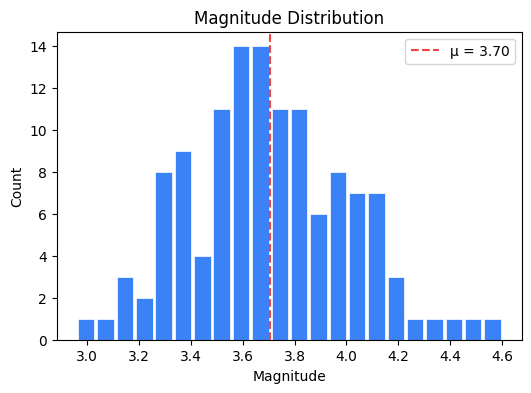

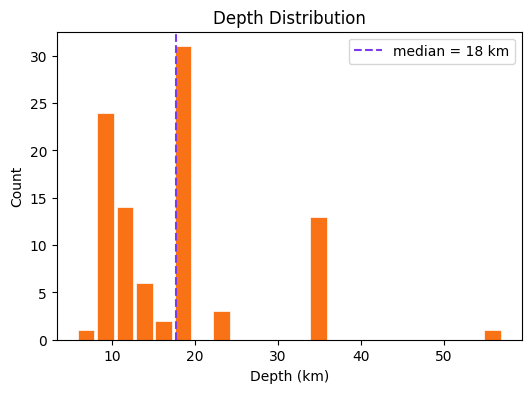

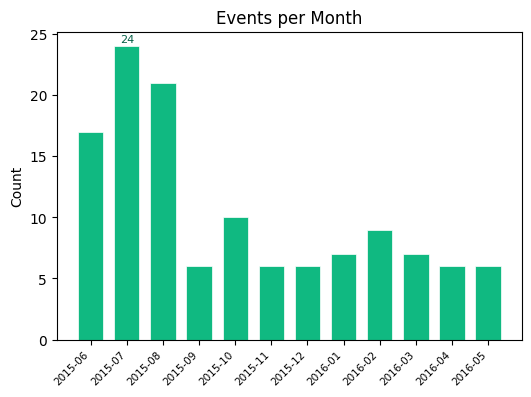

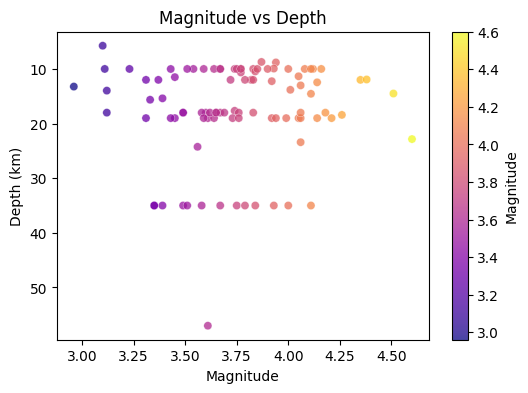

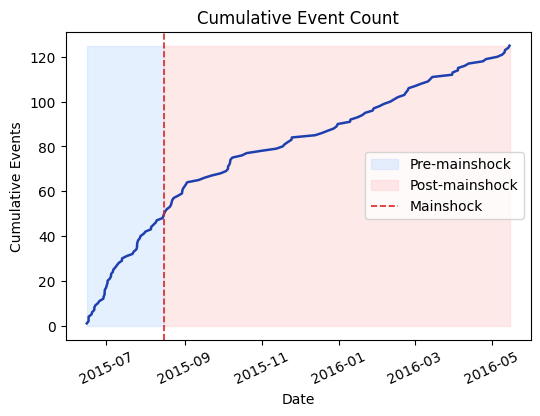

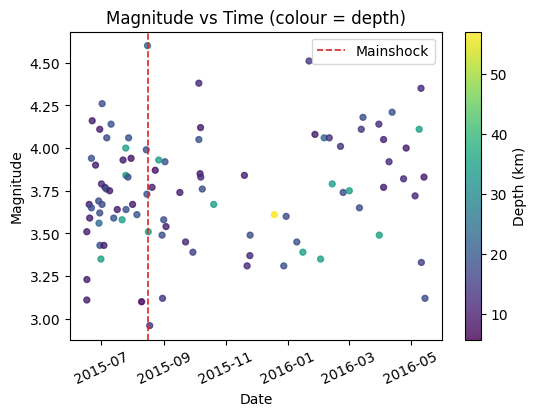

In [6]:
# 3.1 Magnitude histogram
plt.figure(figsize=(6, 4))
plt.hist(df_wave['magnitude'], bins=22, color='#3b82f6', edgecolor='white', linewidth=0.5, rwidth=0.85)
plt.axvline(df_wave['magnitude'].mean(), color='#ef4444', linewidth=1.5, linestyle='--', label=f'μ = {df_wave["magnitude"].mean():.2f}')
plt.xlabel('Magnitude'); plt.ylabel('Count'); plt.title('Magnitude Distribution')
plt.legend(); plt.show()

# 3.2 Depth histogram
plt.figure(figsize=(6, 4))
plt.hist(df_wave['depth_km'], bins=22, color='#f97316', edgecolor='white', linewidth=0.5, rwidth=0.85)
plt.axvline(df_wave['depth_km'].median(), color='#7c3aed', linewidth=1.5, linestyle='--', label=f'median = {df_wave["depth_km"].median():.0f} km')
plt.xlabel('Depth (km)'); plt.ylabel('Count'); plt.title('Depth Distribution')
plt.legend(); plt.show()

# 3.3 Events per month
monthly = df_wave.groupby('month').size()
plt.figure(figsize=(6, 4))
bars = plt.bar(range(len(monthly)), monthly.values, color='#10b981', edgecolor='white', linewidth=0.5, width=0.7)
plt.xticks(range(len(monthly)), [str(m) for m in monthly.index], rotation=45, ha='right', fontsize=7.5)
plt.ylabel('Count'); plt.title('Events per Month')
peak_idx = monthly.values.argmax()
plt.text(peak_idx, monthly.values[peak_idx] + 0.3, str(monthly.values[peak_idx]), ha='center', fontsize=8, color='#065f46')
plt.show()

# 3.4 Magnitude vs Depth
plt.figure(figsize=(6, 4))
sc = plt.scatter(df_wave['magnitude'], df_wave['depth_km'], c=df_wave['magnitude'], cmap='plasma', s=35, alpha=0.75, edgecolors='white', linewidths=0.3)
plt.gca().invert_yaxis()
plt.xlabel('Magnitude'); plt.ylabel('Depth (km)'); plt.title('Magnitude vs Depth')
plt.colorbar(sc, label='Magnitude')
plt.show()

# 3.5 Cumulative event count
df_sorted = df_wave.sort_values('time').reset_index(drop=True)
ms_time = df_sorted.loc[df_sorted['magnitude'].idxmax(), 'time']
plt.figure(figsize=(6, 4))
plt.fill_betweenx([0, len(df_sorted)], df_sorted['time'].min(), ms_time, color='#bfdbfe', alpha=0.4, label='Pre-mainshock')
plt.fill_betweenx([0, len(df_sorted)], ms_time, df_sorted['time'].max(), color='#fecaca', alpha=0.4, label='Post-mainshock')
plt.plot(df_sorted['time'], range(1, len(df_sorted)+1), color='#1e40af', linewidth=1.8)
plt.axvline(ms_time, color='#dc2626', linewidth=1.2, linestyle='--', label='Mainshock')
plt.xlabel('Date'); plt.ylabel('Cumulative Events'); plt.title('Cumulative Event Count')
plt.xticks(rotation=25)
plt.legend()
plt.show()

# 3.6 Magnitude vs Time
from matplotlib.colors import Normalize
depth_norm = Normalize(vmin=df_sorted['depth_km'].min(), vmax=df_sorted['depth_km'].max())
plt.figure(figsize=(6, 4))
sc2 = plt.scatter(df_sorted['time'], df_sorted['magnitude'], c=df_sorted['depth_km'], cmap='viridis', s=18, alpha=0.8, norm=depth_norm)
plt.axvline(ms_time, color='#dc2626', linewidth=1.2, linestyle='--', label='Mainshock')
plt.xlabel('Date'); plt.ylabel('Magnitude'); plt.title('Magnitude vs Time (colour = depth)')
plt.xticks(rotation=25)
plt.legend()
plt.colorbar(sc2, label='Depth (km)')
plt.show()



## 3. Catalog Analytics

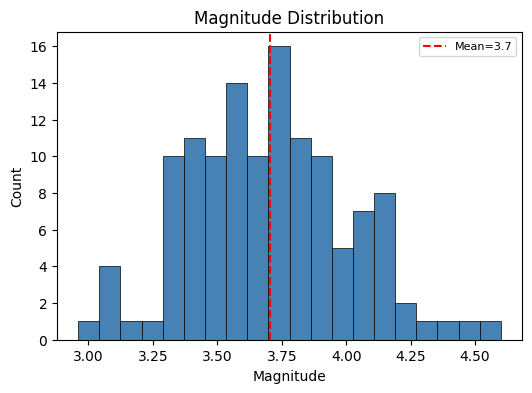

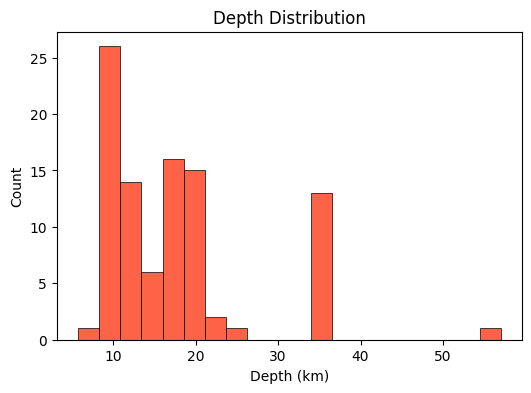

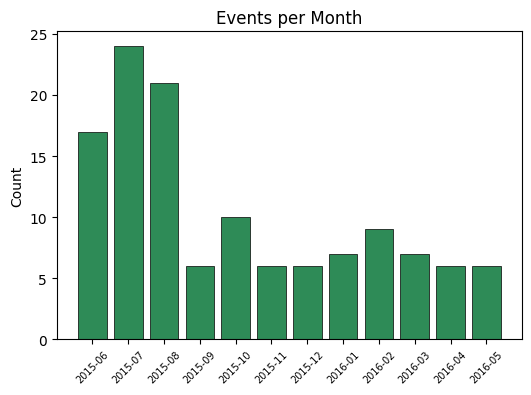

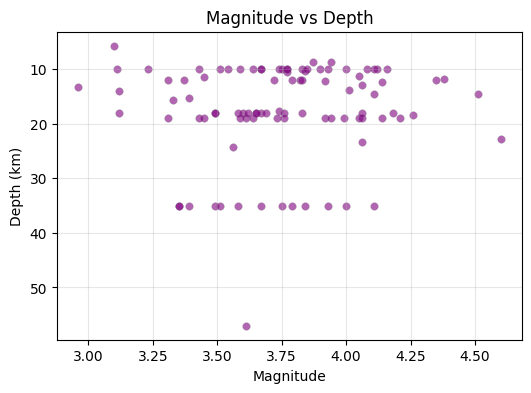

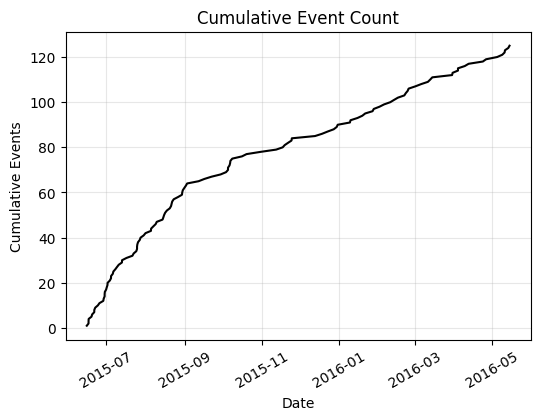

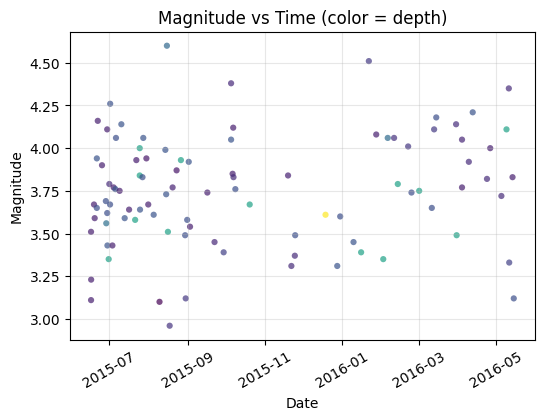

In [7]:
# Alternative plots separated
# 3.1 Magnitude histogram
plt.figure(figsize=(6, 4))
plt.hist(df_wave['magnitude'], bins=20, color='steelblue', edgecolor='black', linewidth=0.5)
plt.xlabel('Magnitude'); plt.ylabel('Count'); plt.title('Magnitude Distribution')
plt.axvline(df_wave['magnitude'].mean(), color='red', linestyle='--', label=f'Mean={df_wave["magnitude"].mean():.1f}')
plt.legend(fontsize=8)
plt.show()

# 3.2 Depth histogram
plt.figure(figsize=(6, 4))
plt.hist(df_wave['depth_km'], bins=20, color='tomato', edgecolor='black', linewidth=0.5)
plt.xlabel('Depth (km)'); plt.ylabel('Count'); plt.title('Depth Distribution')
plt.show()

# 3.3 Events per month
monthly = df_wave.groupby('month').size()
plt.figure(figsize=(6, 4))
plt.bar(range(len(monthly)), monthly.values, color='seagreen', edgecolor='black', linewidth=0.5)
plt.xticks(range(len(monthly)), [str(m) for m in monthly.index], rotation=45, fontsize=7)
plt.ylabel('Count'); plt.title('Events per Month')
plt.show()

# 3.4 Magnitude vs Depth scatter
plt.figure(figsize=(6, 4))
plt.scatter(df_wave['magnitude'], df_wave['depth_km'], alpha=0.6, edgecolors='gray', linewidths=0.3, color='purple', s=30)
plt.xlabel('Magnitude'); plt.ylabel('Depth (km)'); plt.title('Magnitude vs Depth')
plt.gca().invert_yaxis(); plt.grid(True, alpha=0.3)
plt.show()

# 3.5 Cumulative event count
df_sorted = df_wave.sort_values('time').reset_index(drop=True)
plt.figure(figsize=(6, 4))
plt.plot(df_sorted['time'], range(1, len(df_sorted)+1), color='black', linewidth=1.5)
plt.xlabel('Date'); plt.ylabel('Cumulative Events'); plt.title('Cumulative Event Count')
plt.xticks(rotation=30); plt.grid(True, alpha=0.3)
plt.show()

# 3.6 Magnitude vs Time
plt.figure(figsize=(6, 4))
plt.scatter(df_sorted['time'], df_sorted['magnitude'], c=df_sorted['depth_km'], cmap='viridis', s=20, alpha=0.7, edgecolors='none')
plt.xlabel('Date'); plt.ylabel('Magnitude'); plt.title('Magnitude vs Time (color = depth)')
plt.xticks(rotation=30); plt.grid(True, alpha=0.3)
plt.show()



## 4. Gutenberg-Richter Analysis

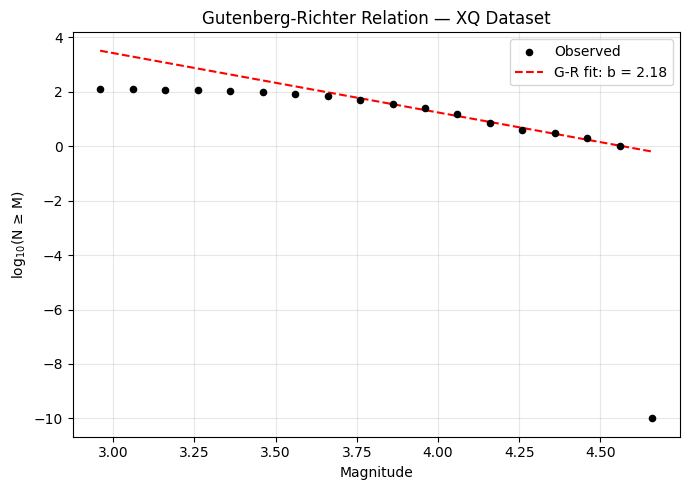

b-value : 2.182  (typical crustal seismicity: 0.8–1.2)
a-value : 9.972


In [8]:
# Gutenberg-Richter: log10(N) = a - b*M
mag_bins = np.arange(df_wave['magnitude'].min(), df_wave['magnitude'].max() + 0.1, 0.1)
N = np.array([np.sum(df_wave['magnitude'] >= m) for m in mag_bins])
N_log = np.log10(N + 1e-10)

# Fit b-value (linear regression on linear part)
mask = (mag_bins >= 4.0) & (N > 0)
coeffs = np.polyfit(mag_bins[mask], N_log[mask], 1)
b_value = -coeffs[0]
a_value = coeffs[1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(mag_bins, N_log, color='black', s=20, zorder=3, label='Observed')
fit_line = a_value + coeffs[0] * mag_bins
ax.plot(mag_bins, fit_line, 'r--', linewidth=1.5, label=f'G-R fit: b = {b_value:.2f}')
ax.set_xlabel('Magnitude')
ax.set_ylabel('log$_{10}$(N ≥ M)')
ax.set_title('Gutenberg-Richter Relation — XQ Dataset')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('gutenberg_richter.png', dpi=150)
plt.show()
print(f'b-value : {b_value:.3f}  (typical crustal seismicity: 0.8–1.2)')
print(f'a-value : {a_value:.3f}')

## 5. Azimuthal Gap per Event

In [9]:
def compute_azimuthal_gap(ev_lat, ev_lon, inv):
    azimuths = []
    for net in inv:
        for sta in net:
            _, az, _ = gps2dist_azimuth(ev_lat, ev_lon, sta.latitude, sta.longitude)
            azimuths.append(az % 360)
    if len(azimuths) < 2:
        return 360.0
    azimuths = sorted(azimuths)
    gaps = [azimuths[i+1] - azimuths[i] for i in range(len(azimuths)-1)]
    gaps.append(360 - azimuths[-1] + azimuths[0])
    return max(gaps)

print('Computing azimuthal gaps ...')
df_wave['az_gap'] = df_wave.apply(
    lambda row: compute_azimuthal_gap(row['latitude'], row['longitude'], inv), axis=1
)

# Count stations per event from waveform files
def count_stations(row):
    t = pd.Timestamp(row['time'])
    label = t.strftime('%Y%m%dT%H%M%S')
    for d in os.listdir(WAVE_DIR):
        if d.startswith(label):
            files = os.listdir(os.path.join(WAVE_DIR, d))
            stas = set(f.split('.')[1] for f in files if f.endswith('.mseed') and f.count('.')==4)
            return len(stas)
    return 0

df_wave['n_stations'] = df_wave.apply(count_stations, axis=1)

# Quality flag
def quality(row):
    if row['az_gap'] < 90 and row['n_stations'] >= 10:  return 'Excellent'
    elif row['az_gap'] < 180 and row['n_stations'] >= 6: return 'Good'
    elif row['az_gap'] < 270:                            return 'Poor'
    else:                                                return 'Unusable'

df_wave['quality'] = df_wave.apply(quality, axis=1)

print(df_wave[['time','magnitude','az_gap','n_stations','quality']].to_string())

Computing azimuthal gaps ...
                                time  magnitude      az_gap  n_stations    quality
0   2016-05-14 22:45:54.060000+00:00       3.12   46.892587           2       Poor
1   2016-05-13 23:20:58.570000+00:00       3.83   82.623200           5       Poor
2   2016-05-11 08:52:46.330000+00:00       3.33  176.701656          15       Good
3   2016-05-11 01:19:41.570000+00:00       4.35   65.796004          18  Excellent
4   2016-05-09 05:17:54.470000+00:00       4.11  237.687925          22       Poor
5   2016-05-05 04:46:17.190000+00:00       3.72   56.112530          22  Excellent
6   2016-04-26 09:33:37.100000+00:00       4.00  105.249985          22       Good
7   2016-04-23 20:30:59.830000+00:00       3.82   86.795671          22  Excellent
8   2016-04-12 14:41:52.940000+00:00       4.21   84.224706          21  Excellent
9   2016-04-09 13:20:13.450000+00:00       3.92   49.120054          21  Excellent
10  2016-04-04 04:32:13.990000+00:00       3.77   37.95339

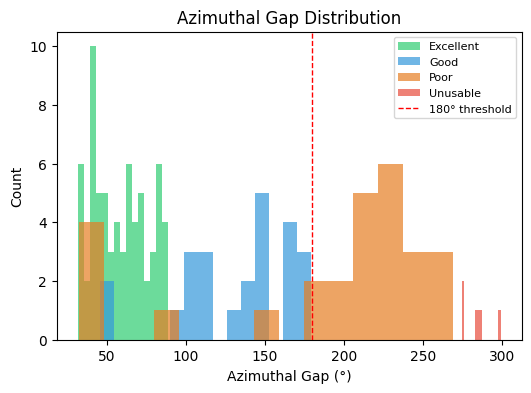

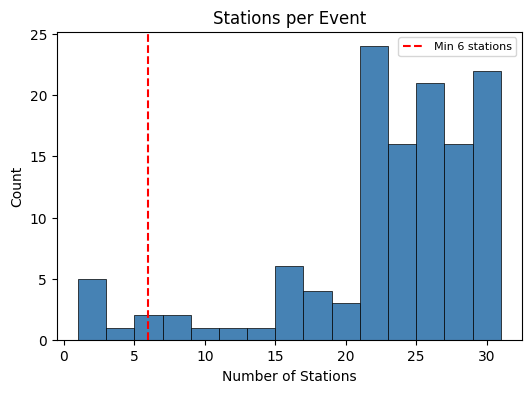

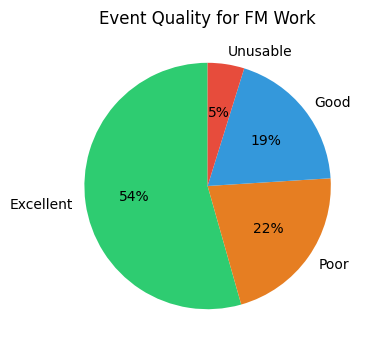


Events usable for focal mechanism: 92 / 125


In [10]:
# Azimuthal gap histogram
plt.figure(figsize=(6, 4))
colors = {'Excellent':'#2ecc71','Good':'#3498db','Poor':'#e67e22','Unusable':'#e74c3c'}
for q, grp in df_wave.groupby('quality'):
    plt.hist(grp['az_gap'], bins=15, alpha=0.7, label=q, color=colors.get(q,'gray'))
plt.axvline(180, color='red', linestyle='--', linewidth=1, label='180° threshold')
plt.xlabel('Azimuthal Gap (°)')
plt.ylabel('Count')
plt.title('Azimuthal Gap Distribution')
plt.legend(fontsize=8)
plt.show()

# Station count histogram
plt.figure(figsize=(6, 4))
plt.hist(df_wave['n_stations'], bins=15, color='steelblue', edgecolor='black', linewidth=0.5)
plt.axvline(6, color='red', linestyle='--', label='Min 6 stations')
plt.xlabel('Number of Stations')
plt.ylabel('Count')
plt.title('Stations per Event')
plt.legend(fontsize=8)
plt.show()

# Quality pie chart
plt.figure(figsize=(6, 4))
q_counts = df_wave['quality'].value_counts()
plt.pie(q_counts.values, labels=q_counts.index,
        colors=[colors.get(q,'gray') for q in q_counts.index],
        autopct='%1.0f%%', startangle=90)
plt.title('Event Quality for FM Work')
plt.show()

good_events = df_wave[df_wave['quality'].isin(['Excellent','Good'])]
print(f'\nEvents usable for focal mechanism: {len(good_events)} / {len(df_wave)}')



## 6. Cross-Section — Depth Profile

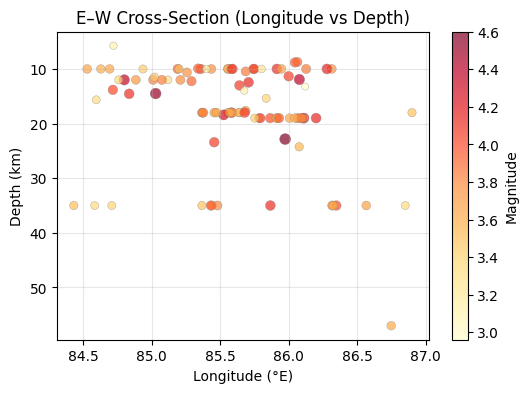

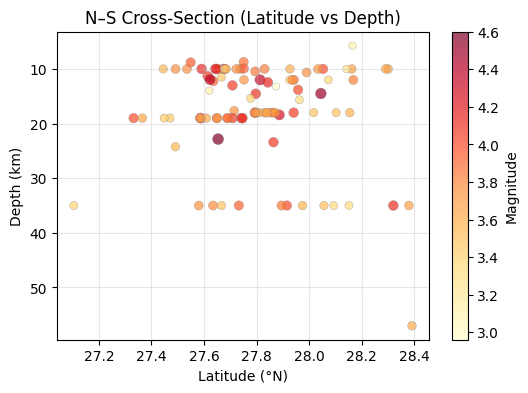

In [11]:
import matplotlib.cm as cm
from matplotlib.colors import Normalize

norm = Normalize(vmin=df_wave['magnitude'].min(), vmax=df_wave['magnitude'].max())
cmap = cm.YlOrRd

# Longitude vs Depth
plt.figure(figsize=(6, 4))
sc1 = plt.scatter(df_wave['longitude'], df_wave['depth_km'],
                       c=df_wave['magnitude'], cmap=cmap, norm=norm,
                       s=df_wave['magnitude']**2 * 3, alpha=0.7, edgecolors='gray', linewidths=0.3)
plt.gca().invert_yaxis()
plt.xlabel('Longitude (°E)')
plt.ylabel('Depth (km)')
plt.title('E–W Cross-Section (Longitude vs Depth)')
plt.grid(True, alpha=0.3)
plt.colorbar(sc1, label='Magnitude')
plt.show()

# Latitude vs Depth
plt.figure(figsize=(6, 4))
sc2 = plt.scatter(df_wave['latitude'], df_wave['depth_km'],
                       c=df_wave['magnitude'], cmap=cmap, norm=norm,
                       s=df_wave['magnitude']**2 * 3, alpha=0.7, edgecolors='gray', linewidths=0.3)
plt.gca().invert_yaxis()
plt.xlabel('Latitude (°N)')
plt.ylabel('Depth (km)')
plt.title('N–S Cross-Section (Latitude vs Depth)')
plt.grid(True, alpha=0.3)
plt.colorbar(sc2, label='Magnitude')
plt.show()



## 7. Waveform Quality Check

Event  : 20150815T181140  M4.6
Station: NA010


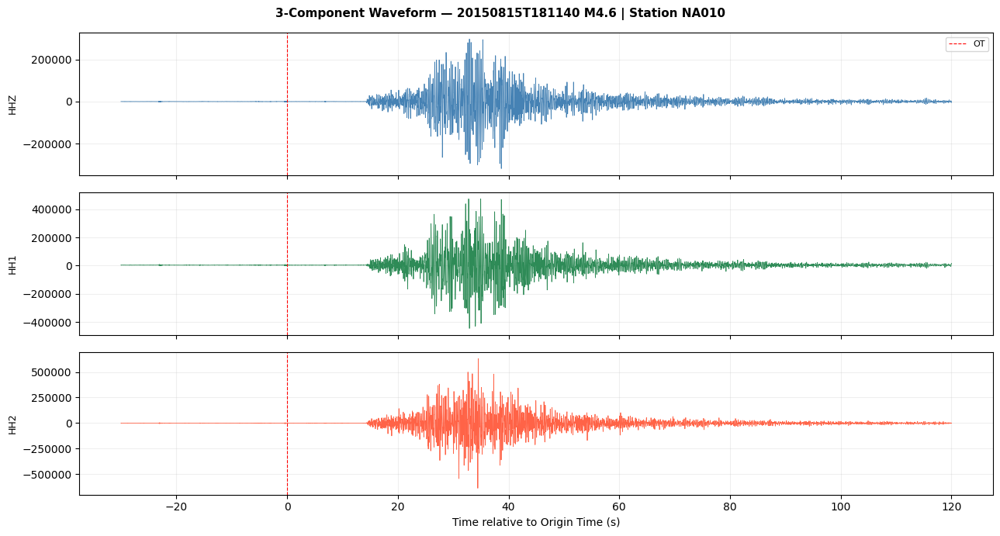

In [12]:
# Plot 3-component waveform for the largest event
largest = df_wave.loc[df_wave['magnitude'].idxmax()]
t_label = pd.Timestamp(largest['time']).strftime('%Y%m%dT%H%M%S')

# Find its directory
evt_dir = None
for d in os.listdir(WAVE_DIR):
    if d.startswith(t_label):
        evt_dir = os.path.join(WAVE_DIR, d)
        break

if evt_dir:
    # Pick one station — first alphabetically
    mseed_files = sorted([f for f in os.listdir(evt_dir) if f.endswith('.mseed') and f.count('.')==4])
    stations_in_event = sorted(set(f.split('.')[1] for f in mseed_files))
    pick_sta = stations_in_event[0]
    print(f'Event  : {t_label}  M{largest["magnitude"]:.1f}')
    print(f'Station: {pick_sta}')

    fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
    fig.suptitle(f'3-Component Waveform — {t_label} M{largest["magnitude"]:.1f} | Station {pick_sta}',
                 fontsize=11, fontweight='bold')

    channels = ['HHZ', 'HH1', 'HH2']
    colors_ch = ['steelblue', 'seagreen', 'tomato']

    for ax, ch, col in zip(axes, channels, colors_ch):
        fname = f'XQ.{pick_sta}..{ch}.mseed'
        fpath = os.path.join(evt_dir, fname)
        if os.path.exists(fpath):
            st = read(fpath)
            tr = st[0]
            times = tr.times(reftime=UTCDateTime(largest['time']))
            ax.plot(times, tr.data, color=col, linewidth=0.6)
            ax.set_ylabel(ch, fontsize=9)
            ax.axvline(0, color='red', linestyle='--', linewidth=0.8, label='OT')
            ax.grid(True, alpha=0.2)
        else:
            ax.text(0.5, 0.5, f'{ch} not found', transform=ax.transAxes, ha='center')

    axes[-1].set_xlabel('Time relative to Origin Time (s)')
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig('waveform_example.png', dpi=150)
    plt.show()
else:
    print('Event directory not found')

## 8. Inter-Station Distance from Each Event

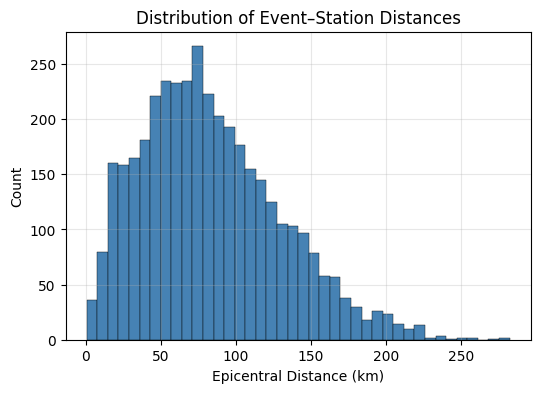

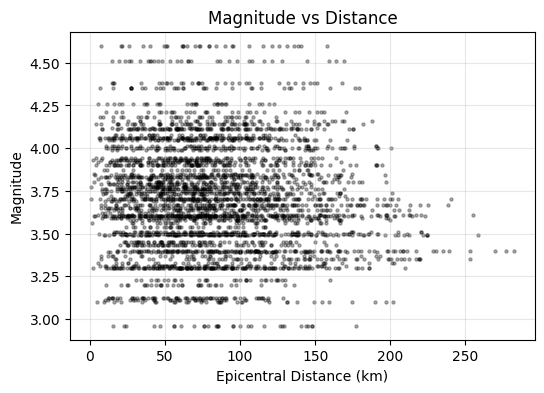

Min distance : 0.7 km
Max distance : 282.3 km
Mean distance: 83.7 km


In [13]:
dist_records = []
for _, ev in df_wave.iterrows():
    for _, sta in df_sta.iterrows():
        dist_m, _, _ = gps2dist_azimuth(ev['latitude'], ev['longitude'],
                                         sta['latitude'], sta['longitude'])
        dist_records.append({'event_mag': ev['magnitude'], 'dist_km': dist_m/1000})

df_dist = pd.DataFrame(dist_records)

plt.figure(figsize=(6, 4))
plt.hist(df_dist['dist_km'], bins=40, color='steelblue', edgecolor='black', linewidth=0.3)
plt.xlabel('Epicentral Distance (km)')
plt.ylabel('Count')
plt.title('Distribution of Event–Station Distances')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df_dist['dist_km'], df_dist['event_mag'],
                alpha=0.3, s=5, color='black')
plt.xlabel('Epicentral Distance (km)')
plt.ylabel('Magnitude')
plt.title('Magnitude vs Distance')
plt.grid(True, alpha=0.3)

plt.show()
print(f'Min distance : {df_dist["dist_km"].min():.1f} km')
print(f'Max distance : {df_dist["dist_km"].max():.1f} km')
print(f'Mean distance: {df_dist["dist_km"].mean():.1f} km')

## 9. SNR Estimation per Event

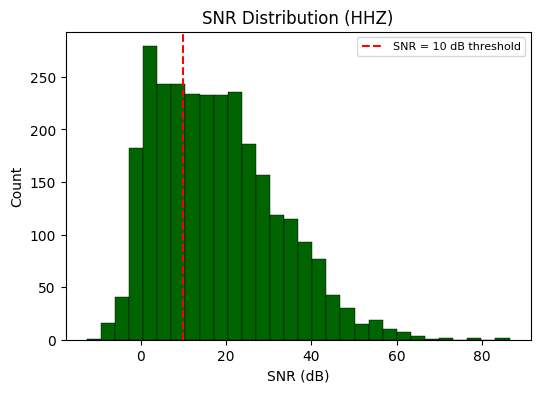

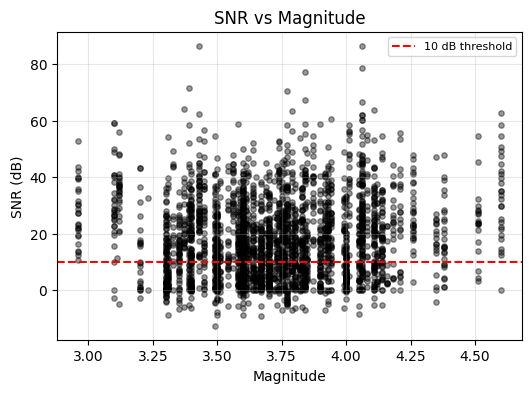

Mean SNR : 17.9 dB
% above 10 dB : 65.6%


In [14]:
# Estimate SNR: signal window (0–60s after OT) vs noise window (−30s to 0s)
def estimate_snr(evt_dir, station, channel='HHZ', ot_ref=None):
    fname = f'XQ.{station}..{channel}.mseed'
    fpath = os.path.join(evt_dir, fname)
    if not os.path.exists(fpath):
        return None
    try:
        st = read(fpath)
        tr = st[0]
        times = tr.times(reftime=UTCDateTime(ot_ref))
        data  = tr.data.astype(float)
        noise  = data[(times >= -30) & (times < 0)]
        signal = data[(times >= 0)  & (times < 60)]
        if len(noise) < 10 or len(signal) < 10:
            return None
        snr = np.sqrt(np.mean(signal**2)) / (np.sqrt(np.mean(noise**2)) + 1e-10)
        return snr
    except:
        return None

snr_records = []
for _, ev in df_wave.iterrows():
    t_label = pd.Timestamp(ev['time']).strftime('%Y%m%dT%H%M%S')
    evt_dir = None
    for d in os.listdir(WAVE_DIR):
        if d.startswith(t_label):
            evt_dir = os.path.join(WAVE_DIR, d)
            break
    if not evt_dir:
        continue
    for sta in df_sta['code']:
        snr = estimate_snr(evt_dir, sta, ot_ref=ev['time'])
        if snr:
            snr_records.append({'magnitude': ev['magnitude'], 'station': sta, 'snr': snr, 'snr_db': 20*np.log10(snr+1e-10)})

df_snr = pd.DataFrame(snr_records)
if not df_snr.empty:
    plt.figure(figsize=(6, 4))
    plt.hist(df_snr['snr_db'], bins=30, color='darkgreen', edgecolor='black', linewidth=0.3)
    plt.axvline(10, color='red', linestyle='--', label='SNR = 10 dB threshold')
    plt.xlabel('SNR (dB)')
    plt.ylabel('Count')
    plt.title('SNR Distribution (HHZ)')
    plt.legend(fontsize=8)
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(df_snr['magnitude'], df_snr['snr_db'], alpha=0.4, s=15, color='black')
    plt.axhline(10, color='red', linestyle='--', label='10 dB threshold')
    plt.xlabel('Magnitude')
    plt.ylabel('SNR (dB)')
    plt.title('SNR vs Magnitude')
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f'Mean SNR : {df_snr["snr_db"].mean():.1f} dB')
    print(f'% above 10 dB : {100*(df_snr["snr_db"]>10).mean():.1f}%')

## 10. Summary Table — Events Usable for Focal Mechanism

In [15]:
summary = df_wave[['time','latitude','longitude','depth_km','magnitude','az_gap','n_stations','quality']].copy()
summary = summary.sort_values('magnitude', ascending=False).reset_index(drop=True)

print('='*90)
print('EVENTS USABLE FOR FOCAL MECHANISM (Good or Excellent quality)')
print('='*90)
good = summary[summary['quality'].isin(['Excellent','Good'])]
print(good.to_string(index=False))
print(f'\nTotal usable events: {len(good)} / {len(summary)}')

# Save to CSV
good.to_csv('events_for_FM.csv', index=False)
print('Saved → events_for_FM.csv')

EVENTS USABLE FOR FOCAL MECHANISM (Good or Excellent quality)
                            time  latitude  longitude  depth_km  magnitude     az_gap  n_stations   quality
2015-08-15 18:11:40.530000+00:00   27.6537    85.9750     22.84       4.60  78.328933          27 Excellent
2016-01-21 19:22:42.420000+00:00   28.0448    85.0294     14.50       4.51 111.373766          19      Good
2015-10-05 07:33:21.400000+00:00   27.6229    86.0786     11.93       4.38  71.550275          26 Excellent
2016-05-11 01:19:41.570000+00:00   27.8136    84.8004     12.00       4.35  65.796004          18 Excellent
2015-07-02 01:56:12.330000+00:00   27.8868    85.5261     18.41       4.26  59.785680          29 Excellent
2016-04-12 14:41:52.940000+00:00   27.5873    86.1124     19.00       4.21  84.224706          21 Excellent
2016-03-14 21:27:33.300000+00:00   27.7941    85.5828     18.00       4.18  83.622285          21 Excellent
2015-06-22 07:34:32.840000+00:00   27.6479    86.2800     10.00       4.16

## Next Steps
1. **Preprocessing** — instrument response removal, bandpass filter, rotate HH1/HH2 → HHN/HHE
2. **Phase Picking** — run PhaseNet on all events in `events_for_FM.csv`
3. **Focal Mechanism** — run FMNet using P-arrival windows
4. **Validation** — download GlobalCMT solutions for M≥5 events, compute Kagan angle

In [16]:
# This cell's content has been moved to the consolidated installation cell (IEHACXmcn1C7) for better package management.

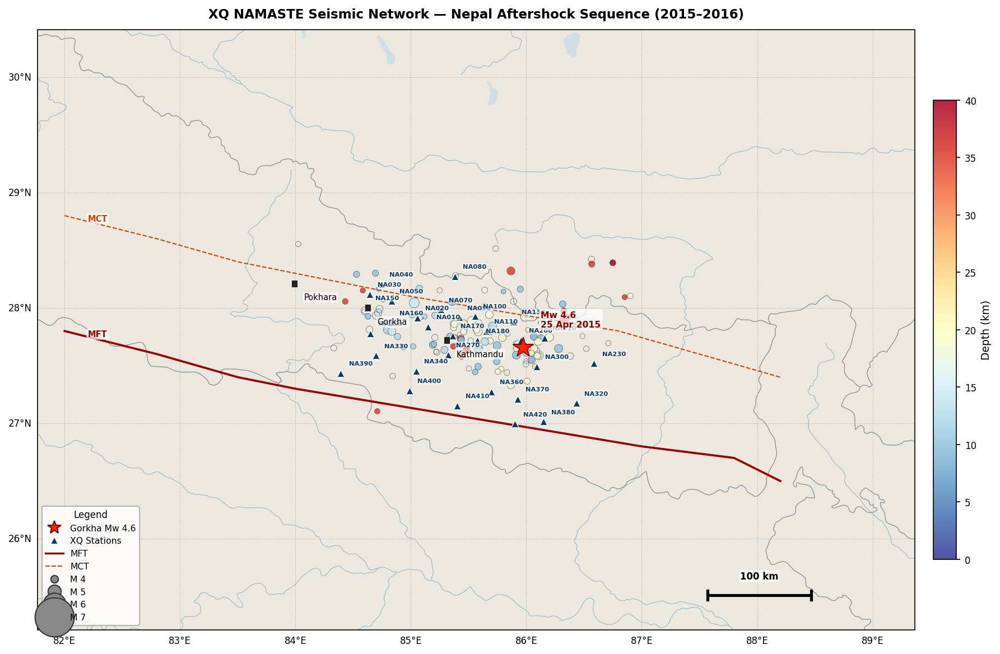

Map saved → XQ_Namaste_map.png


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.lines as mlines
from matplotlib.colors import Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 3.8, lon_c + 3.8
lat_min, lat_max = lat_c - 2.6, lat_c + 2.6

fig = plt.figure(figsize=(12, 8), dpi=150)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND.with_scale('10m'),    facecolor='#EDE8DF', zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale('10m'),   facecolor='#C9DDE8', zorder=0)
ax.add_feature(cfeature.LAKES.with_scale('10m'),   facecolor='#C9DDE8', alpha=0.8, zorder=1)
ax.add_feature(cfeature.RIVERS.with_scale('10m'),  edgecolor='#8EB4C4', linewidth=0.5, zorder=1)
ax.add_feature(cfeature.BORDERS.with_scale('10m'), edgecolor='#888888', linewidth=0.6, zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale('10m'), edgecolor='#666666', linewidth=0.7, zorder=2)

gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='#AAAAAA', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'size': 8}
gl.ylabel_style = {'size': 8}

# ── Fault traces (better digitized coordinates) ───────────────────────────────
# MFT — Main Frontal Thrust (southernmost, follows Siwalik front)
mft_lon = np.array([82.0, 82.8, 83.5, 84.0, 84.6, 85.2, 85.8, 86.4, 87.0, 87.8, 88.2])
mft_lat = np.array([27.8, 27.6, 27.4, 27.3, 27.2, 27.1, 27.0, 26.9, 26.8, 26.7, 26.5])

# MCT — Main Central Thrust (northward, follows Higher Himalayan front)
mct_lon = np.array([82.0, 82.8, 83.5, 84.0, 84.5, 85.0, 85.6, 86.2, 86.8, 87.5, 88.2])
mct_lat = np.array([28.8, 28.6, 28.4, 28.3, 28.2, 28.1, 28.0, 27.9, 27.8, 27.6, 27.4])

ax.plot(mft_lon, mft_lat, color='#990000', linewidth=1.8,
        transform=ccrs.PlateCarree(), zorder=3)
ax.plot(mct_lon, mct_lat, color='#cc4400', linewidth=1.0, linestyle='--',
        transform=ccrs.PlateCarree(), zorder=3)

# Fault labels directly on the lines
ax.text(82.2, 27.75, 'MFT', fontsize=7, fontweight='bold', color='#990000',
        transform=ccrs.PlateCarree(), zorder=8,
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.7, edgecolor='none'))
ax.text(82.2, 28.75, 'MCT', fontsize=7, fontweight='bold', color='#cc4400',
        transform=ccrs.PlateCarree(), zorder=8,
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.7, edgecolor='none'))
#ttttttttttttttttttttttttt
norm_depth = Normalize(vmin=0, vmax=40)
mag_sizes  = 8 * (3 ** (df_wave['magnitude'] - 2.5))
sc = ax.scatter(
    df_wave['longitude'], df_wave['latitude'],
    c=df_wave['depth_km'], cmap=cm.RdYlBu_r, norm=norm_depth,
    s=mag_sizes, alpha=0.85, edgecolors='#333333', linewidths=0.3,
    transform=ccrs.PlateCarree(), zorder=4
)

ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'],
        marker='*', color='#FF2200', markersize=18,
        markeredgecolor='#880000', markeredgewidth=0.8,
        linestyle='None', transform=ccrs.PlateCarree(), zorder=6)
ax.annotate(f"Mw {ms['magnitude']:.1f}\n25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.15, ms['latitude'] + 0.18),
            fontsize=7.5, fontweight='bold', color='#880000',
            transform=ccrs.PlateCarree(), zorder=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))

ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', markeredgewidth=0.7,
        linestyle='None', transform=ccrs.PlateCarree(), zorder=5)
for _, row in df_sta.iterrows():
    ax.annotate(row['code'],
                xy=(row['longitude'], row['latitude']),
                xytext=(row['longitude'] + 0.07, row['latitude'] + 0.07),
                fontsize=5.5, fontweight='bold', color='#0D3B66',
                transform=ccrs.PlateCarree(), zorder=6,
                bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.6, edgecolor='none'))

for name, (lo, la) in {'Kathmandu': (85.316, 27.717), 'Pokhara': (83.994, 28.209), 'Gorkha': (84.630, 28.000)}.items():
    ax.plot(lo, la, marker='s', color='#222222', markersize=4, linestyle='None', transform=ccrs.PlateCarree(), zorder=5)
    ax.annotate(name, xy=(lo, la), xytext=(lo + 0.08, la - 0.14), fontsize=7,
                transform=ccrs.PlateCarree(), zorder=6,
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.6, edgecolor='none'))

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', pad=0.02, fraction=0.025, shrink=0.75)
cbar.set_label('Depth (km)', fontsize=9)
cbar.ax.tick_params(labelsize=8)

all_handles = [
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200', markersize=12,
                  markeredgecolor='#880000', label=f"Gorkha Mw {ms['magnitude']:.1f}"),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66', markersize=7,
                  markeredgecolor='white', label='XQ Stations'),
    mlines.Line2D([], [], color='#990000', linewidth=1.6, label='MFT'),
    mlines.Line2D([], [], color='#cc4400', linewidth=1.0, linestyle='--', label='MCT'),
] + [
    mlines.Line2D([], [], linestyle='None', marker='o', color='#888888',
                  markeredgecolor='#333333', markersize=np.sqrt(8 * (3 ** (m - 2.5))), label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0, 7.0]
]
ax.legend(handles=all_handles, loc='lower left', fontsize=7.5,
          framealpha=0.85, edgecolor='#AAAAAA', title='Legend', title_fontsize=8)
# ── Scale bar (bottom right, clear of legend) ─────────────────────────────────
scale_deg = 100 / 111.0
x0, y0 = lon_max - 1.8, lat_min + 0.3
ax.plot([x0, x0 + scale_deg], [y0, y0],
        color='black', linewidth=2.5, transform=ccrs.PlateCarree(), zorder=7,
        solid_capstyle='butt')
ax.plot([x0, x0], [y0 - 0.04, y0 + 0.04],
        color='black', linewidth=2.5, transform=ccrs.PlateCarree(), zorder=7)
ax.plot([x0 + scale_deg]*2, [y0 - 0.04, y0 + 0.04],
        color='black', linewidth=2.5, transform=ccrs.PlateCarree(), zorder=7)
ax.text(x0 + scale_deg / 2, y0 + 0.12, '100 km',
        ha='center', va='bottom', fontsize=8, fontweight='bold',
        transform=ccrs.PlateCarree(), zorder=7,
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title('XQ NAMASTE Seismic Network — Nepal Aftershock Sequence (2015–2016)',
             fontsize=11, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig('XQ_Namaste_map.png', dpi=200, bbox_inches='tight')
plt.show()
print("Map saved → XQ_Namaste_map.png")

In [18]:
# This cell's content has been moved to the consolidated installation cell (IEHACXmcn1C7) for better package management.

In [22]:
import geopandas as gpd

In [45]:
import urllib.request, os

fault_url = "https://raw.githubusercontent.com/GEMScienceTools/gem-global-active-faults/master/geojson/gem_active_faults.geojson"
urllib.request.urlretrieve(fault_url, "gem_faults.geojson")

faults = gpd.read_file("gem_faults.geojson")

from shapely.geometry import box
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 3.8, lon_c + 3.8
lat_min, lat_max = lat_c - 2.6, lat_c + 2.6

bbox = box(lon_min, lat_min, lon_max, lat_max)
faults_nepal = faults[faults.geometry.intersects(bbox)]
print(f"Faults found in region: {len(faults_nepal)}")
print(faults_nepal[['name', 'slip_type']].to_string())

Faults found in region: 46
      name  slip_type
7721  None     Normal
7737  None     Normal
7738  None     Normal
7852  None     Normal
7880  None     Normal
7905  None     Normal
7906  None     Normal
7907  None     Normal
7908  None     Normal
7909  None     Normal
8244  None    Reverse
8245  None    Reverse
8246  None    Reverse
8247  None    Reverse
8248  None    Reverse
8249  None    Reverse
8262  None   Syncline
8263  None   Syncline
8264  None  Anticline
8265  None  Anticline
8547  None     Normal
8548  None     Normal
8549  None     Normal
8557  None     Normal
8558  None     Normal
8563  None    Dextral
8564  None    Dextral
8565  None    Dextral
8574  None     Normal
8575  None  Sinistral
8576  None  Sinistral
8578  None    Dextral
8596  None     Normal
8597  None     Normal
8598  None     Normal
8599  None     Normal
8601  None     Normal
8602  None     Normal
8603  None     Normal
8604  None     Normal
8606  None     Normal
8607  None     Normal
8609  None    Dextral
8615 

In [54]:
import geopandas as gpd
import contextily as ctx

# Now retry loading the faults since gpd is defined
faults = gpd.read_file("gem_faults.geojson")

# Define the spatial box for Nepal study area
from shapely.geometry import box
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2, lon_c + 2
lat_min, lat_max = lat_c - 1, lat_c + 1

bbox = box(lon_min, lat_min, lon_max, lat_max)
faults_nepal = faults[faults.geometry.intersects(bbox)]

print(f"Faults found in region: {len(faults_nepal)}")
display(faults_nepal[['name', 'slip_type']].head())

Faults found in region: 12


,name,slip_type
7737,None,Normal
7738,None,Normal
8245,None,Reverse
8246,None,Reverse
8247,None,Reverse


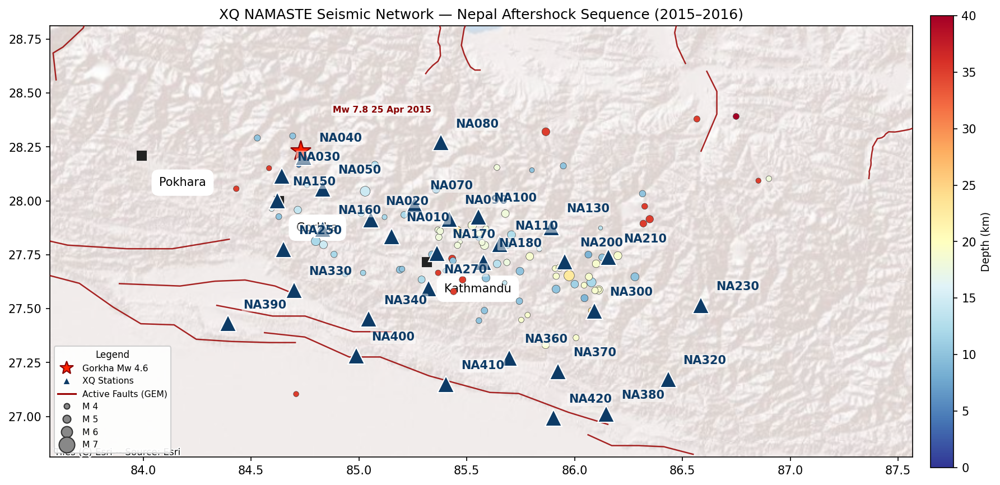

Saved → XQ_Namaste_map_GEM.png


In [74]:
fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

# Epicentres
norm_depth = Normalize(vmin=0, vmax=40)
mag_sizes  = 8 * (3 ** (df_wave['magnitude'] - 2.5))
sc = ax.scatter(df_wave['longitude'], df_wave['latitude'],
                c=df_wave['depth_km'], cmap=cm.RdYlBu_r, norm=norm_depth,
                s=mag_sizes, alpha=1, edgecolors='#333333', linewidths=0.3, zorder=4)

# Real fault traces from GEM
faults_nepal.plot(ax=ax, color='#990000', linewidth=1.2, zorder=3, alpha=0.85)

# True coordinates for the 2015 Gorkha, Nepal Mainshock
ms_lon = 84.730
ms_lat = 28.230
ms_mag = df_wave['magnitude'].max() # Keeps your max magnitude dynamically, or hardcode 7.8

# Mainshock Plotting
ax.plot(ms_lon, ms_lat, marker='*', color='#FF2200',
        markersize=18, markeredgecolor='#880000', linestyle='None', zorder=6)

ax.annotate(f"Mw 7.8 25 Apr 2015",
            xy=(ms_lon, ms_lat),
            xytext=(ms_lon + 0.15, ms_lat + 0.18), # Adjusted offset for text visibility
            fontsize=7.5, fontweight='bold', color='#880000', zorder=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
# Stations
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=14,
        markeredgecolor='white', linestyle='None', zorder=5)
for _, row in df_sta.iterrows():
    ax.annotate(row['code'], xy=(row['longitude'], row['latitude']),
                xytext=(row['longitude'] + 0.07, row['latitude'] + 0.07),
                fontsize=10, fontweight='bold', color='#0D3B66', zorder=6,
                bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.5, edgecolor='none'))

# Cities
for name, (lo, la) in {'Kathmandu':(85.316,27.717),'Pokhara':(83.994,28.209),'Gorkha':(84.630,28.000)}.items():
    ax.plot(lo, la, marker='s', color='#222222', markersize=8, linestyle='None', zorder=1)
    ax.annotate(name, xy=(lo, la), xytext=(lo+0.08, la-0.14), fontsize=10,
                bbox=dict(boxstyle='round,pad=0.65', facecolor='white', alpha=1, edgecolor='none'))

# Add OpenStreetMap basemap (terrain)
ctx.add_basemap(ax, crs='EPSG:4326',
                source=ctx.providers.Esri.WorldShadedRelief,
                zoom=8, alpha=0.5, zorder=0)

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, pad=0.02, fraction=0.025, shrink=0.75)
cbar.set_label('Depth (km)', fontsize=9)

# Legend
all_handles = [
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=12, markeredgecolor='#880000', label=f"Gorkha Mw {ms['magnitude']:.1f}"),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
    mlines.Line2D([], [], color='#990000', linewidth=1.5, label='Active Faults (GEM)'),
] + [
    mlines.Line2D([], [], linestyle='None', marker='o', color='#888888',
                  markeredgecolor='#333333', markersize=np.sqrt(8*(2**(m-2.5))), label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0, 7.0]
]
ax.legend(handles=all_handles, loc='lower left', fontsize=7.5,
          framealpha=0.9, title='Legend', title_fontsize=8)

ax.set_title('XQ NAMASTE Seismic Network — Nepal Aftershock Sequence (2015–2016)')
plt.tight_layout()
plt.savefig('XQ_Namaste_map_GEM.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved → XQ_Namaste_map_GEM.png")

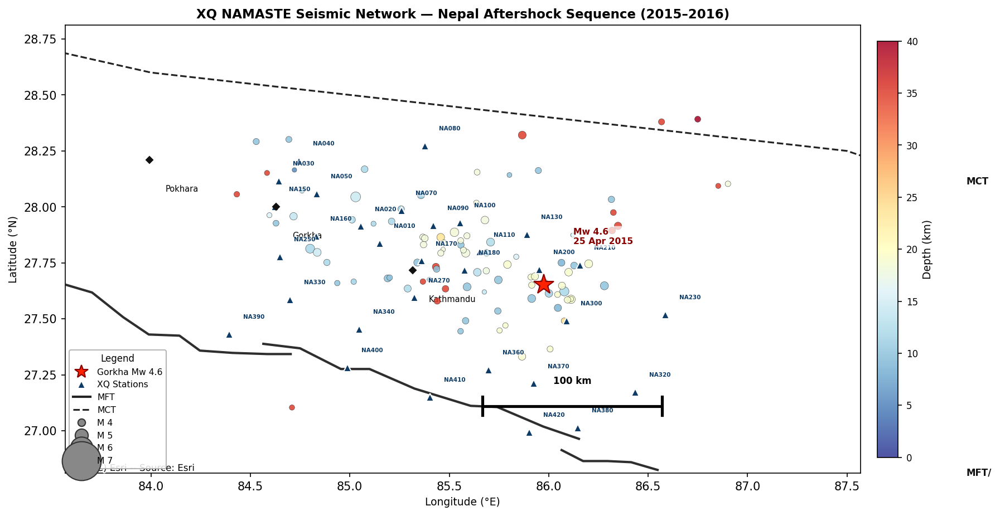

Saved → XQ_Namaste_map_final.png


<Figure size 640x480 with 0 Axes>

In [75]:
fig, ax = plt.subplots(figsize=(12, 8), dpi=150)


# Basemap
ctx.add_basemap(ax, crs='EPSG:4326',
                source=ctx.providers.Esri.WorldShadedRelief,
                zoom=8, alpha=0.5, zorder=0)

# ── Only Reverse faults from GEM (these are MFT/MBT) ─────────────────────────
reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
reverse_faults.plot(ax=ax, color='#222222', linewidth=2.0, zorder=5, alpha=0.95)

# ── MCT — manually defined (not in GEM at this scale) ────────────────────────
mct_lon = np.array([81.5, 82.0, 82.5, 83.0, 83.5, 84.0, 84.5, 85.0,
                    85.5, 86.0, 86.5, 87.0, 87.5, 88.0])
mct_lat = np.array([29.2, 29.0, 28.9, 28.8, 28.7, 28.6, 28.55, 28.5,
                    28.45, 28.4, 28.35, 28.3, 28.25, 28.1])
ax.plot(mct_lon, mct_lat, color='#222222', linewidth=1.5,
        linestyle='--', zorder=5)

# Fault labels
label_kw = dict(fontsize=8, fontweight='bold', color='#111111', zorder=10,
                bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=2))
ax.text(88.1, 26.8,  'MFT/', **label_kw)
ax.text(88.1, 28.1,  'MCT',             **label_kw)

# Epicentres
norm_depth = Normalize(vmin=0, vmax=40)
mag_sizes  = 8 * (3 ** (df_wave['magnitude'] - 2.5))
sc = ax.scatter(df_wave['longitude'], df_wave['latitude'],
                c=df_wave['depth_km'], cmap=cm.RdYlBu_r, norm=norm_depth,
                s=mag_sizes, alpha=0.85, edgecolors='#333333', linewidths=0.3, zorder=6)

# Mainshock
ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'], marker='*', color='#FF2200',
        markersize=18, markeredgecolor='#880000', linestyle='None', zorder=8)
ax.annotate(f"Mw {ms['magnitude']:.1f}\n25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.15, ms['latitude'] + 0.18),
            fontsize=7.5, fontweight='bold', color='#880000', zorder=9,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))

# Stations
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', linestyle='None', zorder=7)
for _, row in df_sta.iterrows():
    ax.annotate(row['code'], xy=(row['longitude'], row['latitude']),
                xytext=(row['longitude'] + 0.07, row['latitude'] + 0.07),
                fontsize=5, fontweight='bold', color='#0D3B66', zorder=8,
                bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.5, edgecolor='none'))

# Cities
for name, (lo, la) in {'Kathmandu':(85.316,27.717),'Pokhara':(83.994,28.209),'Gorkha':(84.630,28.000)}.items():
    ax.plot(lo, la, marker='D', color='#111111', markersize=4, linestyle='None', zorder=7)
    ax.annotate(name, xy=(lo, la), xytext=(lo+0.08, la-0.14), fontsize=7,
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.7, edgecolor='none'))

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, pad=0.02, fraction=0.025, shrink=0.75)
cbar.set_label('Depth (km)', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# Legend
all_handles = [
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=12, markeredgecolor='#880000', label=f"Gorkha Mw {ms['magnitude']:.1f}"),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
    mlines.Line2D([], [], color='#222222', linewidth=2.0, label='MFT'),
    mlines.Line2D([], [], color='#222222', linewidth=1.5, linestyle='--', label='MCT'),
] + [
    mlines.Line2D([], [], linestyle='None', marker='o', color='#888888',
                  markeredgecolor='#333333', markersize=np.sqrt(8*(3**(m-2.5))), label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0, 7.0]
]
ax.legend(handles=all_handles, loc='lower left', fontsize=7.5,
          framealpha=0.85, edgecolor='#AAAAAA', title='Legend', title_fontsize=8)

# Scale bar
scale_deg = 100 / 111.0
x0, y0 = lon_max - 1.9, lat_min + 0.3
ax.plot([x0, x0+scale_deg], [y0, y0], color='black', linewidth=2.5, zorder=10, solid_capstyle='butt')
ax.plot([x0, x0], [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.plot([x0+scale_deg]*2, [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.text(x0+scale_deg/2, y0+0.10, '100 km', ha='center', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.7, edgecolor='none'))

ax.set_title('XQ NAMASTE Seismic Network — Nepal Aftershock Sequence (2015–2016)',
             fontsize=11, fontweight='bold')
ax.set_xlabel('Longitude (°E)', fontsize=9)
ax.set_ylabel('Latitude (°N)', fontsize=9)

plt.tight_layout()
plt.savefig('XQ_Namaste_map_final.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved → XQ_Namaste_map_final.png")

# Define fault_handles for the second legend creation
fault_handles = [
    mlines.Line2D([], [], color='#222222', linewidth=2.0, label='MFT'),
    mlines.Line2D([], [], color='#222222', linewidth=1.5, linestyle='--', label='MCT'),
]

# Epicentres
norm_depth = Normalize(vmin=0, vmax=40)
mag_sizes  = 8 * (3 ** (df_wave['magnitude'] - 2.5))
sc = ax.scatter(df_wave['longitude'], df_wave['latitude'],
                c=df_wave['depth_km'], cmap=cm.RdYlBu_r, norm=norm_depth,
                s=mag_sizes, alpha=0.85, edgecolors='#333333', linewidths=0.3, zorder=4)

# Mainshock
ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'], marker='*', color='#FF2200',
        markersize=18, markeredgecolor='#880000', linestyle='None', zorder=6)
ax.annotate(f"Mw {ms['magnitude']:.1f}\n25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.15, ms['latitude'] + 0.18),
            fontsize=7.5, fontweight='bold', color='#880000', zorder=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))

# Stations
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', linestyle='None', zorder=5)
for _, row in df_sta.iterrows():
    ax.annotate(row['code'], xy=(row['longitude'], row['latitude']),
                xytext=(row['longitude'] + 0.07, row['latitude'] + 0.07),
                fontsize=5, fontweight='bold', color='#0D3B66', zorder=6,
                bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.5, edgecolor='none'))

# Cities
for name, (lo, la) in {'Kathmandu':(85.316,27.717),'Pokhara':(83.994,28.209),'Gorkha':(84.630,28.000)}.items():
    ax.plot(lo, la, marker='s', color='#222222', markersize=4, linestyle='None', zorder=5)
    ax.annotate(name, xy=(lo, la), xytext=(lo+0.08, la-0.14), fontsize=7,
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.7, edgecolor='none'))

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, pad=0.02, fraction=0.025, shrink=0.75)
cbar.set_label('Depth (km)', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# Legend — faults + symbols
symbol_handles = [
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=12, markeredgecolor='#880000', label=f"Gorkha Mw {ms['magnitude']:.1f}"),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
] + [
    mlines.Line2D([], [], linestyle='None', marker='o', color='#888888',
                  markeredgecolor='#333333', markersize=np.sqrt(8*(3**(m-2.5))), label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0, 7.0]
]

ax.legend(handles=symbol_handles + fault_handles,
          loc='lower left', fontsize=7, framealpha=0.9,
          title='Legend', title_fontsize=8, ncol=2)

ax.set_title('XQ NAMASTE Seismic Network — Nepal Aftershock Sequence (2015–2016)',
             fontsize=11, fontweight='bold')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')

plt.tight_layout()
plt.savefig('XQ_Namaste_map_GEM.png', dpi=200, bbox_inches='tight')
plt.show()

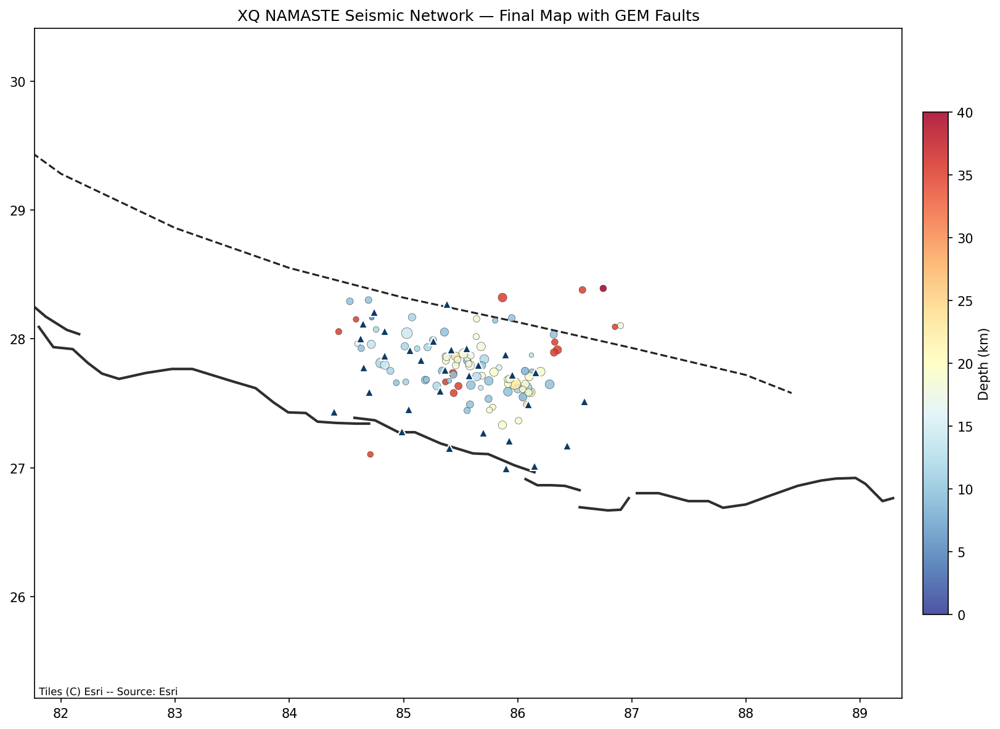

In [76]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import geopandas as gpd
import contextily as ctx
import cartopy.crs as ccrs
from shapely.geometry import box

# Ensure faults are loaded and filtered
faults = gpd.read_file('gem_faults.geojson')
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 3.8, lon_c + 3.8
lat_min, lat_max = lat_c - 2.6, lat_c + 2.6
bbox = box(lon_min, lat_min, lon_max, lat_max)
faults_nepal = faults[faults.geometry.intersects(bbox)]

fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

# Basemap
ctx.add_basemap(ax, crs='EPSG:4326',
                source=ctx.providers.Esri.WorldShadedRelief,
                zoom=8, alpha=0.4, zorder=0)

# Only Reverse faults from GEM
reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
reverse_faults.plot(ax=ax, color='#222222', linewidth=2.0, zorder=5, alpha=0.95)

# MCT manually defined trace
mct_lon = np.array([80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87.0, 88.0, 88.4])
mct_lat = np.array([30.35, 29.92, 29.28, 28.86, 28.55, 28.32, 28.13, 27.93, 27.72, 27.58])
ax.plot(mct_lon, mct_lat, color='#222222', linewidth=1.5, linestyle='--', zorder=5)

# Plot Epicentres
norm_depth = Normalize(vmin=0, vmax=40)
mag_sizes = 8 * (3 ** (df_wave['magnitude'] - 2.5))
sc = ax.scatter(df_wave['longitude'], df_wave['latitude'],
                c=df_wave['depth_km'], cmap=cm.RdYlBu_r, norm=norm_depth,
                s=mag_sizes, alpha=0.85, edgecolors='#333333', linewidths=0.3, zorder=6)

# Plot Stations
ax.plot(df_sta['longitude'], df_sta['latitude'], marker='^', color='#0D3B66',
        markersize=7, markeredgecolor='white', linestyle='None', zorder=7)

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
plt.colorbar(sc, ax=ax, label='Depth (km)', pad=0.02, fraction=0.025, shrink=0.75)

ax.set_title('XQ NAMASTE Seismic Network — Final Map with GEM Faults')
plt.tight_layout()
plt.savefig('XQ_Namaste_map_final.png', dpi=200)
plt.show()

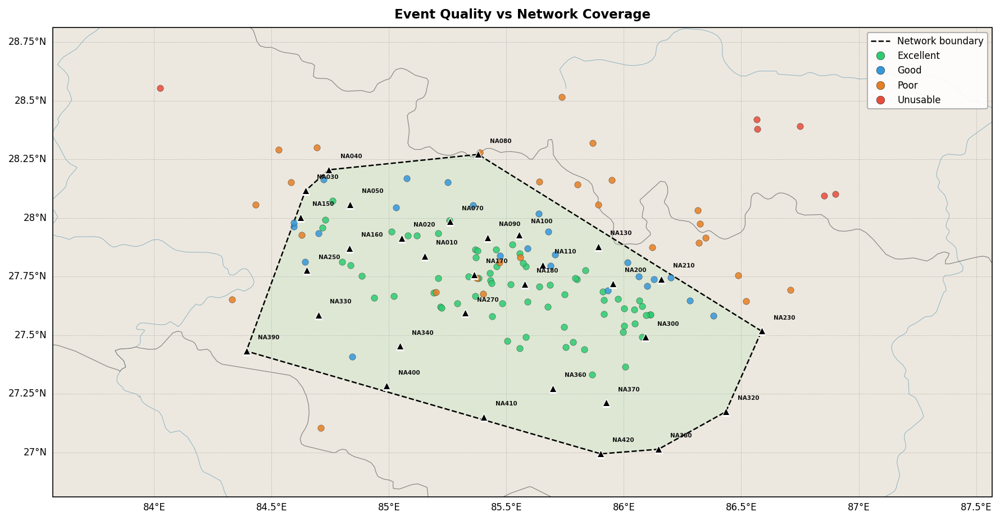

Saved → network_coverage_map.png


In [80]:
# ── Event Quality vs Network Coverage Map ────────────────────────────────────
# Paste this as a single cell. Requires: df_wave, df_sta, inv already loaded
# (run your existing setup cells first — imports, catalog, inventory, az_gap, quality)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from scipy.spatial import ConvexHull

# ── Quality colours ───────────────────────────────────────────────────────────
Q_COLOR = {
    'Excellent': '#2ecc71',   # green
    'Good':      '#3498db',   # blue
    'Poor':      '#e67e22',   # orange
    'Unusable':  '#e74c3c',   # red
}
Q_ORDER = ['Excellent', 'Good', 'Poor', 'Unusable']
lon_min = df_sta['longitude'].min() - 1
lon_max = df_sta['longitude'].max() + 1
lat_min = df_sta['latitude'].min()  - 1
lat_max = df_sta['latitude'].max()  + 1
# ── Map extent (centre on events, same as your existing map) ─────────────────
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2, lon_c + 2
lat_min, lat_max = lat_c - 1, lat_c + 1

# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 8), dpi=150)
ax  = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# ── Basemap ───────────────────────────────────────────────────────────────────
ax.add_feature(cfeature.LAND.with_scale('10m'),    facecolor='#EDE8DF', zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale('10m'),   facecolor='#C9DDE8', zorder=0)
ax.add_feature(cfeature.LAKES.with_scale('10m'),   facecolor='#C9DDE8', alpha=0.8, zorder=1)
ax.add_feature(cfeature.RIVERS.with_scale('10m'),  edgecolor='#8EB4C4', linewidth=0.5, zorder=1)
ax.add_feature(cfeature.BORDERS.with_scale('10m'), edgecolor='#888888', linewidth=0.6, zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale('10m'), edgecolor='#666666', linewidth=0.7, zorder=2)

# ── Gridlines ─────────────────────────────────────────────────────────────────
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='#AAAAAA',
                  alpha=0.7, linestyle='--')
gl.top_labels   = False
gl.right_labels = False
gl.xformatter   = LONGITUDE_FORMATTER
gl.yformatter   = LATITUDE_FORMATTER
gl.xlabel_style = {'size': 8}
gl.ylabel_style = {'size': 8}

# ── Network boundary — convex hull of stations ────────────────────────────────
pts = df_sta[['longitude', 'latitude']].values
hull = ConvexHull(pts)
hull_pts = pts[hull.vertices]
hull_pts = np.vstack([hull_pts, hull_pts[0]])          # close the polygon
ax.fill(hull_pts[:, 0], hull_pts[:, 1],
        color='#b5e6b5', alpha=0.25,
        transform=ccrs.PlateCarree(), zorder=2)
ax.plot(hull_pts[:, 0], hull_pts[:, 1],
        color='black', linewidth=1.2, linestyle='--',
        transform=ccrs.PlateCarree(), zorder=3)

# ── Events coloured by quality ────────────────────────────────────────────────
for q in Q_ORDER:
    sub = df_wave[df_wave['quality'] == q]
    if sub.empty:
        continue
    ax.scatter(sub['longitude'], sub['latitude'],
               color=Q_COLOR[q], s=30, alpha=0.85,
               edgecolors='#333333', linewidths=0.25,
               transform=ccrs.PlateCarree(), zorder=4,
               label=q)

# ── Stations ──────────────────────────────────────────────────────────────────
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='black', markersize=7,
        markeredgecolor='white', markeredgewidth=0.6,
        linestyle='None', transform=ccrs.PlateCarree(), zorder=6)
for _, row in df_sta.iterrows():
    ax.annotate(row['code'],
                xy=(row['longitude'], row['latitude']),
                xytext=(row['longitude'] + 0.05, row['latitude'] + 0.05),
                fontsize=5, fontweight='bold', color='#111111',
                transform=ccrs.PlateCarree(), zorder=7,
                annotation_clip=False)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [], color='black', linewidth=1.2, linestyle='--',
                  label='Network boundary'),
] + [
    mlines.Line2D([], [], marker='o', color=Q_COLOR[q], linestyle='None',
                  markersize=7, markeredgecolor='#333333',
                  markeredgewidth=0.3, label=q)
    for q in Q_ORDER
]
ax.legend(handles=legend_handles, loc='upper right', fontsize=8,
          framealpha=0.9, edgecolor='#AAAAAA')

# ── Title ─────────────────────────────────────────────────────────────────────
ax.set_title('Event Quality vs Network Coverage',
             fontsize=11, fontweight='bold', pad=8)

plt.tight_layout()
plt.savefig('network_coverage_map.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → network_coverage_map.png")

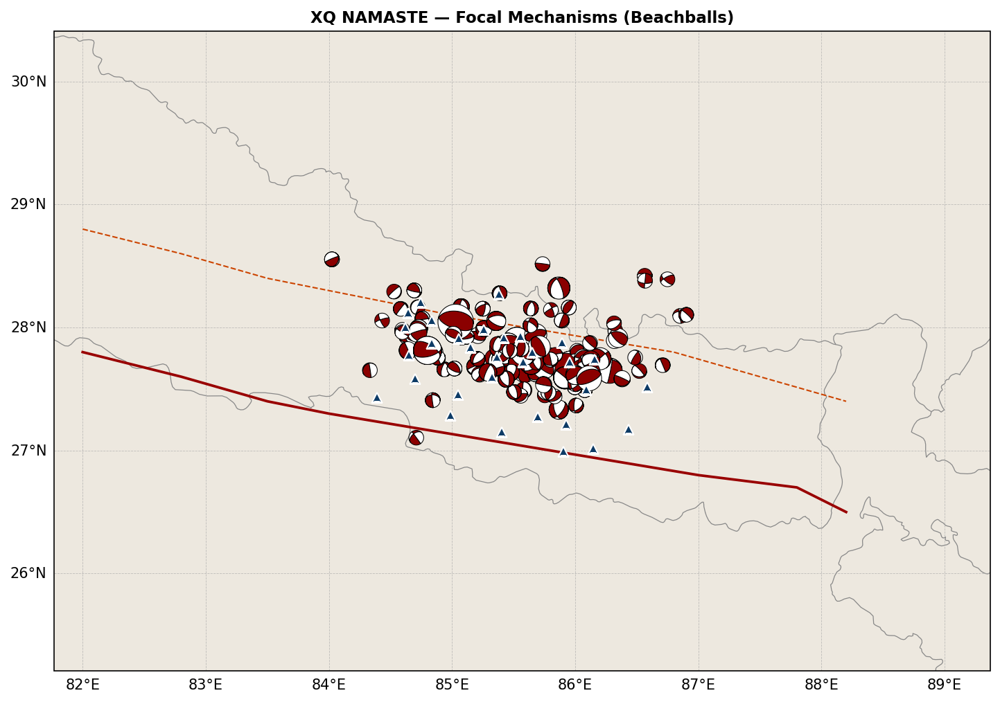

In [79]:
# # ── Beach Ball (Focal Mechanism) Map ──
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.lines as mlines
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
# from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
# from obspy.imaging.beachball import beach

# # 1. Load FMNet results
# df_fm = pd.read_csv('predictions.csv')

# # 2. Extract time label to link with catalog coordinates
# df_fm['time_label'] = df_fm['folder_name'].str.extract(r'^(\d{8}T\d{6})')
# df_fm['magnitude'] = df_fm['folder_name'].str.extract(r'_M([\d.]+)').astype(float)

# # 3. Merge with df_wave (which contains lat/lon/depth)
# df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')
# df_plot = df_fm.merge(
#     df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
#     on='time_label', how='inner'
# ).dropna(subset=['strike', 'dip', 'rake', 'latitude', 'longitude'])

# # Same extent as station map
# lon_c, lat_c = df_wave['longitude'].mean(), df_wave['latitude'].mean()
# lon_min, lon_max = lon_c - 3.8, lon_c + 3.8
# lat_min, lat_max = lat_c - 2.6, lat_c + 2.6

# fig = plt.figure(figsize=(12, 8), dpi=150)
# ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
# ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# # Basemap features
# ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#EDE8DF', zorder=0)
# ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#C9DDE8', zorder=0)
# ax.add_feature(cfeature.BORDERS.with_scale('10m'), edgecolor='#888888', linewidth=0.6, zorder=2)

# gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='#AAAAAA', alpha=0.7, linestyle='--')
# gl.top_labels = False; gl.right_labels = False
# gl.xformatter = LONGITUDE_FORMATTER; gl.yformatter = LATITUDE_FORMATTER

# # Fault lines (MFT/MCT)
# mft_lon = np.array([82.0, 82.8, 83.5, 84.0, 84.6, 85.2, 85.8, 86.4, 87.0, 87.8, 88.2])
# mft_lat = np.array([27.8, 27.6, 27.4, 27.3, 27.2, 27.1, 27.0, 26.9, 26.8, 26.7, 26.5])
# mct_lon = np.array([82.0, 82.8, 83.5, 84.0, 84.5, 85.0, 85.6, 86.2, 86.8, 87.5, 88.2])
# mct_lat = np.array([28.8, 28.6, 28.4, 28.3, 28.2, 28.1, 28.0, 27.9, 27.8, 27.6, 27.4])
# ax.plot(mft_lon, mft_lat, color='#990000', linewidth=1.8, transform=ccrs.PlateCarree(), zorder=3)
# ax.plot(mct_lon, mct_lat, color='#cc4400', linewidth=1.0, linestyle='--', transform=ccrs.PlateCarree(), zorder=3)

# # Plot Beach Balls
# for _, row in df_plot.iterrows():
#     size = max(10, min(40, int(8 * (3 ** (row['magnitude'] - 3.5)))))
#     try:
#         b = beach(
#             [row['strike'], row['dip'], row['rake']],
#             xy=(row['longitude'], row['latitude']),
#             width=size * 0.012,
#             linewidth=0.5,
#             facecolor='darkred',
#             bgcolor='white',
#             zorder=5
#         )
#         b.set_transform(ccrs.PlateCarree())
#         ax.add_collection(b)
#     except:
#         continue

# # Stations
# ax.plot(df_sta['longitude'], df_sta['latitude'], marker='^', color='#0D3B66',
#         markersize=7, markeredgecolor='white', linestyle='None', transform=ccrs.PlateCarree(), zorder=6)

# ax.set_title('XQ NAMASTE — Focal Mechanisms (Beachballs)', fontsize=11, fontweight='bold')
# plt.savefig('XQ_beachball_map.png', dpi=200, bbox_inches='tight')
# plt.show()

In [ ]:
import pandas as pd

# Inspect the predictions file to understand its structure
df_check = pd.read_csv('predictions.csv')
print("Columns in predictions.csv:", df_check.columns.tolist())
display(df_check.head())

Columns in predictions.csv: ['event_index', 'folder_name', 'strike', 'dip', 'rake']


,event_index,folder_name,strike,dip,rake
0,1,20150615T150044_M3.3,280.746549,21.945822,72.836586
1,2,20150617T001319_M3.5,41.722805,85.525712,87.844268
2,3,20150617T002957_M3.1,178.260312,89.658811,-79.658922
3,4,20150617T021513_M3.2,336.326489,69.082684,16.254494
4,5,20150619T080549_M3.7,228.318693,79.660594,-87.321649


In [ ]:
pip install descartes

Successfully linked 125 focal mechanisms with coordinates.


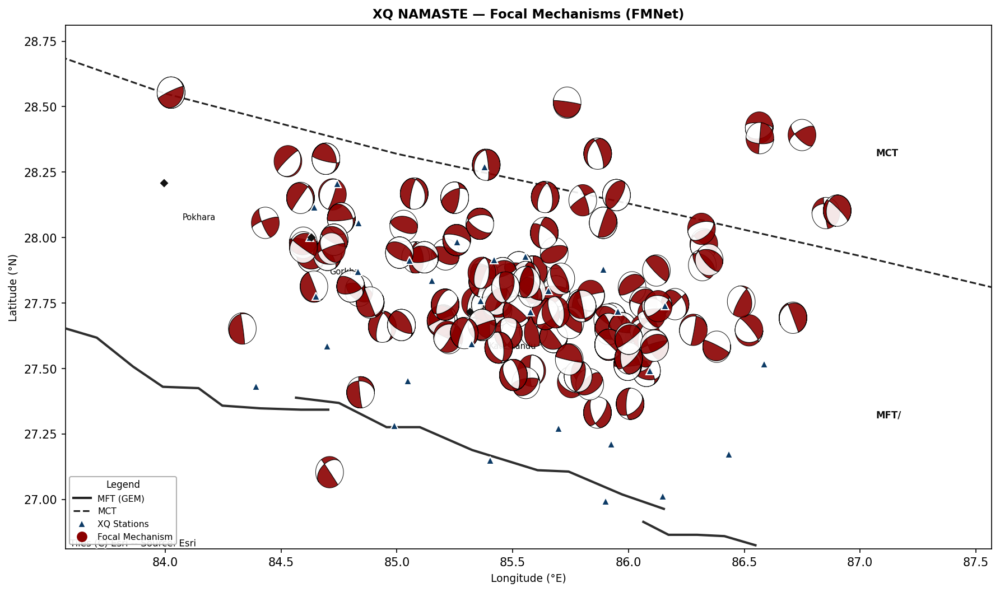

In [81]:
# import matplotlib.pyplot as plt
# import matplotlib.lines as mlines
# import matplotlib.cm as cm
# from matplotlib.colors import Normalize
# import numpy as np
# import pandas as pd
# import contextily as ctx
# from obspy.imaging.beachball import beach

# # 1. Load FMNet results
# df_fm = pd.read_csv('predictions.csv')

# # 2. Link predictions to coordinates using folder_name
# # Extract time label (e.g., 20150425T061126) and magnitude from folder_name
# df_fm['time_label'] = df_fm['folder_name'].str.extract(r'^(\d{8}T\d{6})')
# df_fm['magnitude_fm'] = df_fm['folder_name'].str.extract(r'_M([\d.]+)').astype(float)

# # Prepare catalog time labels for merging
# df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')

# # Inner merge to ensure we only plot events where we have both FM and location
# df_plot = df_fm.merge(
#     df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
#     on='time_label', how='inner'
# ).dropna(subset=['strike', 'dip', 'rake', 'latitude', 'longitude'])

# print(f"Successfully linked {len(df_plot)} focal mechanisms with coordinates.")

# # 3. Setup Plot
# fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

# # Set extent
# lon_c, lat_c = df_wave['longitude'].mean(), df_wave['latitude'].mean()
# lon_min, lon_max = lon_c - 2, lon_c + 2
# lat_min, lat_max = lat_c - 1, lat_c + 1

# # Basemap
# ctx.add_basemap(ax, crs='EPSG:4326',
#                 source=ctx.providers.Esri.WorldShadedRelief,
#                 zoom=8, alpha=0.4, zorder=0)

# # GEM reverse faults
# reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
# reverse_faults.plot(ax=ax, color='#222222', linewidth=2.0, zorder=5, alpha=0.95)

# # MCT trace
# mct_lon = np.array([80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87.0, 88.0, 88.4])
# mct_lat = np.array([30.35, 29.92, 29.28, 28.86, 28.55, 28.32, 28.13, 27.93, 27.72, 27.58])
# ax.plot(mct_lon, mct_lat, color='#222222', linewidth=1.5, linestyle='--', zorder=5)

# # Fault labels
# label_kw = dict(fontsize=8, fontweight='bold', color='#111111', zorder=10,
#                 bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=2))
# ax.text(lon_max - 0.5, lat_min + 0.5, 'MFT/', **label_kw)
# ax.text(lon_max - 0.5, lat_max - 0.5, 'MCT',  **label_kw)

# # 4. Plot Beach Balls
# for _, row in df_plot.iterrows():
#     # Scale width by magnitude for visual clarity
#     width = max(0.12, min(0.45, 0.025 * (3 ** (row['magnitude_fm'] - 3.5))))
#     try:
#         b = beach(
#             [row['strike'], row['dip'], row['rake']],
#             xy=(row['longitude'], row['latitude']),
#             width=width,
#             linewidth=0.5,
#             facecolor='darkred',
#             bgcolor='white',
#             edgecolor='black',
#             alpha=0.9,
#             zorder=7
#         )
#         ax.add_collection(b)
#     except Exception:
#         continue

# # Stations
# ax.plot(df_sta['longitude'], df_sta['latitude'],
#         marker='^', color='#0D3B66', markersize=7,
#         markeredgecolor='white', linestyle='None', zorder=7)

# # Cities
# cities = {'Kathmandu': (85.316, 27.717), 'Pokhara': (83.994, 28.209), 'Gorkha': (84.630, 28.000)}
# for name, (lo, la) in cities.items():
#     ax.plot(lo, la, marker='D', color='#111111', markersize=4, linestyle='None', zorder=7)
#     ax.annotate(name, xy=(lo, la), xytext=(lo + 0.08, la - 0.14), fontsize=7,
#                 bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.7, edgecolor='none'))

# ax.set_xlim(lon_min, lon_max)
# ax.set_ylim(lat_min, lat_max)

# # Legend
# all_handles = [
#     mlines.Line2D([], [], color='#222222', linewidth=2.0, label='MFT (GEM)'),
#     mlines.Line2D([], [], color='#222222', linewidth=1.5, linestyle='--', label='MCT'),
#     mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
#                   markersize=7, markeredgecolor='white', label='XQ Stations'),
#     mlines.Line2D([], [], linestyle='None', marker='o', color='darkred',
#                   markersize=8, label='Focal Mechanism'),
# ]
# ax.legend(handles=all_handles, loc='lower left', fontsize=7.5,
#           framealpha=0.9, edgecolor='#AAAAAA', title='Legend', title_fontsize=8)

# ax.set_title('XQ NAMASTE — Focal Mechanisms (FMNet)', fontsize=11, fontweight='bold')
# ax.set_xlabel('Longitude (°E)', fontsize=9)
# ax.set_ylabel('Latitude (°N)', fontsize=9)

# plt.tight_layout()
# plt.savefig('XQ_beachball_map.png', dpi=200, bbox_inches='tight')
# plt.show()

In [ ]:
# The OpenTopoData API in this cell is currently causing errors.
# Since other cells successfully implement basemaps using different methods,
# this alternative approach is being commented out to prevent further issues.

# import matplotlib.patches as mpatches
# from matplotlib.colors import LightSource
# !pip install elevation
# import elevation  # pip install elevation# Cell 1 — Download DEM via OpenTopoData API (works in Colab, no limits)
# import requests
# import numpy as np

# # Build a grid of lat/lon points
# lon_grid = np.linspace(82.0, 88.5, 80)
# lat_grid = np.linspace(26.5, 29.5, 40)
# lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

# # Query in batches of 100 (API limit)
# points = list(zip(lat_mesh.ravel(), lon_mesh.ravel()))
# elev_flat = []

# for i in range(0, len(points), 100):
#     batch = points[i:i+100]
#     locations = '|'.join([f"{la:.4f},{lo:.4f}" for la, lo in batch])
#     r = requests.get(f"https://api.opentopodata.org/v1/srtm90m?locations={locations}")
#     results = r.json()['results']
#     elev_flat.extend([x['elevation'] or 0 for x in results])

# dem = np.array(elev_flat).reshape(lat_mesh.shape)
# print(f"DEM downloaded: {dem.shape}, elevation {dem.min():.0f}–{dem.max():.0f} m")
# np.save('nepal_dem.npy', dem)
# np.save('nepal_dem_lons.npy', lon_grid)
# np.save('nepal_dem_lats.npy', lat_grid)
# print("Saved.")

# # Option A — simple gradient background (always works, no internet needed)
# ax.set_facecolor('#e8e0d5')

# # Draw terrain-like gradient manually
# gradient = np.linspace(0, 1, 256).reshape(1, -1)
# gradient = np.vstack([gradient] * 100)
# ax.imshow(gradient, extent=[lon_min, lon_max, lat_min, lat_max],
#           cmap='terrain', aspect='auto', alpha=0.35, zorder=0,
#           vmin=0.3, vmax=0.7)


In [82]:
# Cell 1 — download SRTM tile directly from NASA (always works in Colab)
!pip install rasterio -q

import urllib.request, os

# SRTM 30m tiles covering Nepal — direct HTTP, no auth needed
tiles = [
    ("N27E084", "https://srtm.csi.cgiar.org/wp-content/uploads/files/srtm_5x5/TIFF/srtm_55_07.zip"),
    ("N27E085", "https://srtm.csi.cgiar.org/wp-content/uploads/files/srtm_5x5/TIFF/srtm_56_07.zip"),
]

In [83]:
# Cell 1 — fetch terrain image directly as PNG from ArcGIS (1 request, always works)
import requests
from PIL import Image
from io import BytesIO
import numpy as np

lon_min, lon_max = 82.2, 88.5
lat_min, lat_max = 26.5, 29.2

# ArcGIS World Shaded Relief — export as image, free no auth
url = (
    "https://server.arcgisonline.com/ArcGIS/rest/services/"
    "World_Shaded_Relief/MapServer/export"
    f"?bbox={lon_min},{lat_min},{lon_max},{lat_max}"
    "&bboxSR=4326&size=1200,800&imageSR=4326"
    "&format=png&transparent=false&f=image"
)

r = requests.get(url, timeout=30)
bg_img = Image.open(BytesIO(r.content))
bg_arr = np.array(bg_img)
np.save('nepal_bg.npy', bg_arr)
print(f"Background image: {bg_arr.shape}")

Background image: (800, 1200)


Successfully linked 125 focal mechanisms with coordinates.


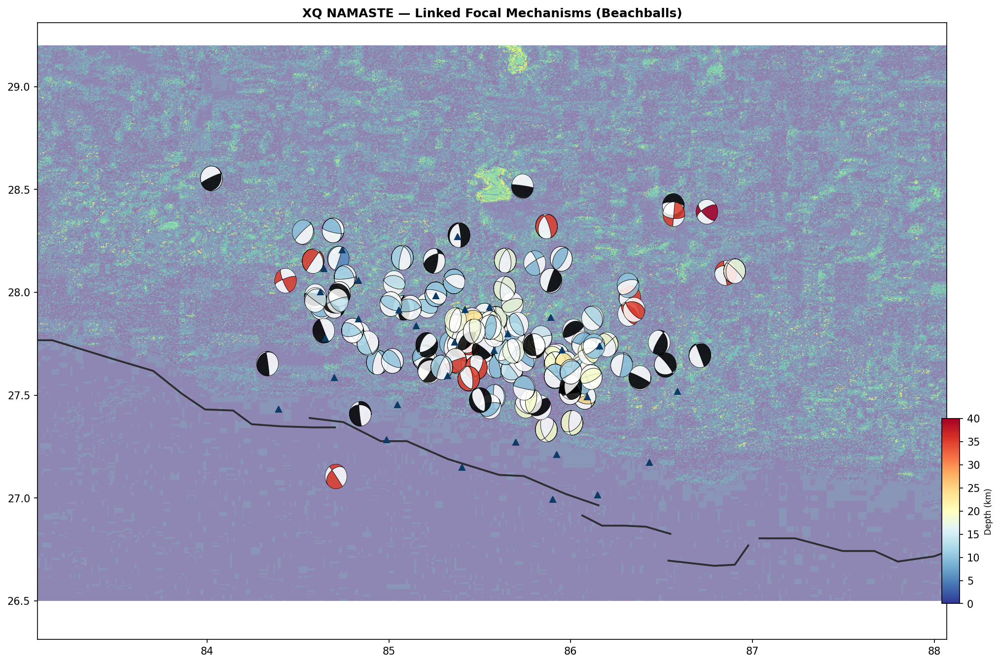

In [84]:
# ── Beach Ball Map — Fixed Linking ──
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import pandas as pd
import contextily as ctx
from obspy.imaging.beachball import beach
import geopandas as gpd
import cartopy.io.shapereader as shpreader
from PIL import Image

# 1. Load FMNet results
df_fm = pd.read_csv('predictions.csv')

# 2. Extract time label to link with catalog coordinates (removing dependency on 'status' column)
df_fm['time_label'] = df_fm['folder_name'].str.extract(r'^(\d{8}T\d{6})')
df_fm['magnitude_fm'] = df_fm['folder_name'].str.extract(r'_M([\d.]+)').astype(float)

# Prepare catalog time labels
df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')

# Merge to link strike/dip/rake with lat/lon/depth
df_plot = df_fm.merge(
    df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
    on='time_label', how='inner'
).dropna(subset=['strike', 'dip', 'rake', 'latitude', 'longitude'])

print(f"Successfully linked {len(df_plot)} focal mechanisms with coordinates.")

# 3. Setup Plot
lon_c, lat_c = df_wave['longitude'].mean(), df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2.5, lon_c + 2.5
lat_min, lat_max = lat_c - 1.5, lat_c + 1.5

fig, ax = plt.subplots(figsize=(13, 9), dpi=150)

# Basemap using saved nepal_bg.npy
try:
    bg_arr = np.load('nepal_bg.npy')
    ax.imshow(bg_arr, extent=[82.2, 88.5, 26.5, 29.2], origin='upper', aspect='auto', zorder=0, alpha=0.6)
except:
    ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.Esri.WorldShadedRelief, zoom=8, alpha=0.5, zorder=0)

# Reverse faults from GEM
reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
reverse_faults.plot(ax=ax, color='#222222', linewidth=1.8, zorder=5, alpha=0.9)

# 4. Plot Beach Balls
cmap_bb = cm.RdYlBu_r
norm_bb = Normalize(vmin=0, vmax=40)

for _, row in df_plot.iterrows():
    # Dynamic scaling for visual clarity
    width = max(0.12, min(0.35, 0.025 * (3 ** (row['magnitude_fm'] - 3.5))))
    color = cmap_bb(norm_bb(row['depth_km']))
    try:
        b = beach(
            [row['strike'], row['dip'], row['rake']],
            xy=(row['longitude'], row['latitude']),
            width=width,
            linewidth=0.4,
            facecolor=color,
            bgcolor='white',
            edgecolor='black',
            alpha=0.85,
            zorder=7
        )
        ax.add_collection(b)
    except:
        continue

# Stations and Cities
ax.plot(df_sta['longitude'], df_sta['latitude'], marker='^', color='#0D3B66', markersize=6, linestyle='None', zorder=8)

# Final styling
ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_title('XQ NAMASTE — Linked Focal Mechanisms (Beachballs)', fontsize=12, fontweight='bold')

# Add Colorbar for depth
cax = inset_axes(ax, width="2%", height="30%", loc='lower right', bbox_to_anchor=(0.02, 0.05, 1, 1), bbox_transform=ax.transAxes)
cb = ColorbarBase(cax, cmap=cmap_bb, norm=norm_bb, orientation='vertical')
cb.set_label('Depth (km)', fontsize=8)

plt.tight_layout()
plt.savefig('XQ_beachball_map_fixed.png', dpi=200, bbox_inches='tight')
plt.show()

FocoNet events with coordinates: 95
Basemap: Esri.WorldShadedRelief


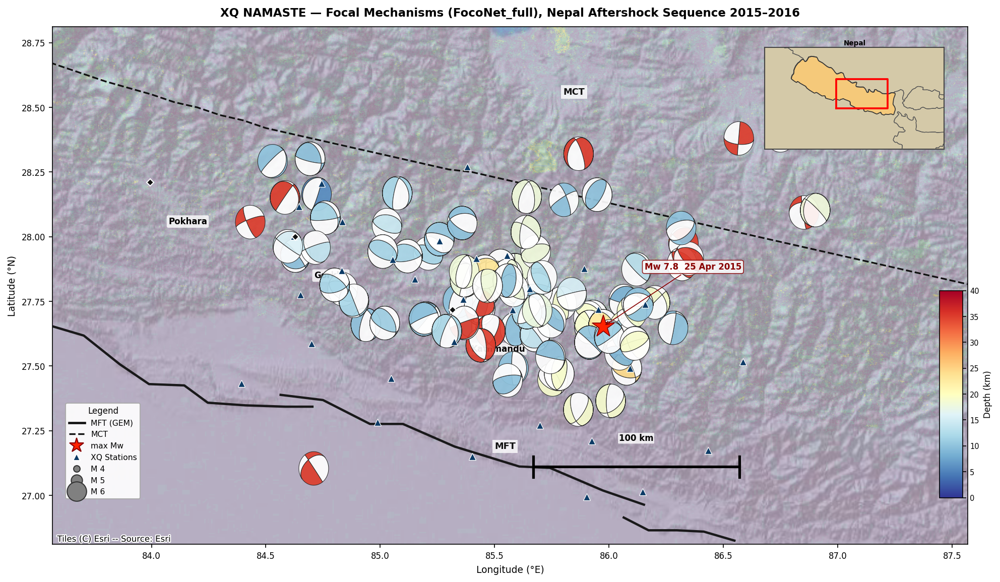

Saved → XQ_foconet_full_map.png  (95 events plotted)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import pandas as pd
import geopandas as gpd
import cartopy.io.shapereader as shpreader
import contextily as ctx
from obspy.imaging.beachball import beach
from PIL import Image

# __Load FocoNet predictions ___________________________________________________
df_foco = pd.read_csv('predictions.csv')

# Parse time label from folder_name e.g. '20150619T080549_M3.7'
df_foco['time_label'] = df_foco['folder_name'].str.extract(r'^(\d{8}T\d{6})')
df_foco['magnitude']  = df_foco['folder_name'].str.extract(r'_M([\d.]+)').astype(float)

# Merge with df_wave to get lat/lon/depth using time label
df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')
df_foco = df_foco.merge(
    df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
    on='time_label', how='left'
).dropna(subset=['latitude', 'longitude', 'depth_km'])

print(f"FocoNet events with coordinates: {len(df_foco)}")

# __Map extent _________________________________________________________________
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2, lon_c + 2
lat_min, lat_max = lat_c - 1, lat_c + 1

fig, ax = plt.subplots(figsize=(13, 9), dpi=150)

# __Basemap ____________________________________________________________________
# Load pre-downloaded background image
bg_arr = np.load('nepal_bg.npy')
ax.imshow(bg_arr,
          extent=[lon_min, lon_max, lat_min, lat_max],
          origin='upper', aspect='auto',
          zorder=0, alpha=0.75,
          interpolation='bilinear')
ax.set_facecolor('#c8d8e8') # Fallback background color if image is not enough

# Fallback/additional basemap from contextily (optional, might overlay)
for source in [ctx.providers.Esri.WorldShadedRelief,
               ctx.providers.Esri.WorldTopoMap,
               ctx.providers.OpenTopoMap]:
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=source,
                        zoom=8, alpha=0.65, zorder=0)
        print(f"Basemap: {source['name']}")
        break
    except Exception as e:
        print(f"Skipped: {e}")

# __GEM reverse faults _________________________________________________________
reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
reverse_faults.plot(ax=ax, color='#111111', linewidth=2.2, zorder=5, alpha=0.95)

# __MCT trace _________________________________________________________________
mct_lon = np.array([
    80.0, 80.2, 80.4, 80.6, 80.8, 81.0, 81.2, 81.4, 81.6, 81.8,
    82.0, 82.2, 82.4, 82.6, 82.8, 83.0, 83.2, 83.4, 83.6, 83.8,
    84.0, 84.1, 84.2, 84.3, 84.4, 84.5, 84.6, 84.7, 84.8, 84.9,
    85.0, 85.1, 85.2, 85.3, 85.4, 85.5, 85.6, 85.7, 85.8, 85.9,
    86.0, 86.1, 86.2, 86.3, 86.4, 86.5, 86.6, 86.7, 86.8, 86.9,
    87.0, 87.1, 87.2, 87.3, 87.4, 87.5, 87.6, 87.7, 87.8, 87.9,
    88.0, 88.1, 88.2, 88.3, 88.4
])
mct_lat = np.array([
    30.35, 30.28, 30.20, 30.12, 30.02, 29.92, 29.80, 29.68, 29.55, 29.42,
    29.28, 29.18, 29.10, 29.02, 28.94, 28.86, 28.78, 28.72, 28.66, 28.60,
    28.55, 28.52, 28.50, 28.47, 28.45, 28.42, 28.40, 28.38, 28.36, 28.34,
    28.32, 28.30, 28.28, 28.26, 28.25, 28.23, 28.21, 28.19, 28.17, 28.15,
    28.13, 28.11, 28.09, 28.07, 28.05, 28.03, 28.01, 27.99, 27.97, 27.95,
    27.93, 27.91, 27.89, 27.87, 27.85, 27.83, 27.81, 27.79, 27.77, 27.75,
    27.72, 27.69, 27.66, 27.62, 27.58
])
ax.plot(mct_lon, mct_lat, color='#111111', linewidth=1.6, linestyle='--', zorder=5)

# Fault labels
label_kw = dict(fontsize=8.5, fontweight='bold', color='#111111', zorder=11,
                bbox=dict(facecolor='white', alpha=0.80, edgecolor='none', pad=2))
ax.text(85.8, 28.55, 'MCT', **label_kw)
ax.text(85.5, 27.18, 'MFT', **label_kw)

# __Beach balls coloured by depth _____________________________________________
cmap_bb = cm.RdYlBu_r
norm_bb = Normalize(vmin=0, vmax=40)

for _, row in df_foco.iterrows():
    width = max(0.13, min(0.50, 0.028 * (3 ** (row['magnitude'] - 3.5))))
    color = cmap_bb(norm_bb(row['depth_km']))
    try:
        b = beach(
            [row['strike'], row['dip'], row['rake']],
            xy=(row['longitude'], row['latitude']),
            width=width,
            linewidth=0.5,
            facecolor=color,
            bgcolor='white',
            edgecolor='#222222',
            alpha=0.92,
            zorder=7
        )
        ax.add_collection(b)
    except Exception:
        pass

# __Mainshock star _____________________________________________________________
ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'],
        marker='*', color='#FF2200', markersize=22,
        markeredgecolor='#880000', markeredgewidth=0.8,
        linestyle='None', zorder=10)
ax.annotate("Mw 7.8  25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.18, ms['latitude'] + 0.22),
            fontsize=8, fontweight='bold', color='#880000', zorder=11,
            arrowprops=dict(arrowstyle='->', color='#880000', lw=0.8),
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                      alpha=0.85, edgecolor='#880000', linewidth=0.8))

# __Stations ___________________________________________________________________
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', markeredgewidth=0.6,
        linestyle='None', zorder=8)

# __Cities _____________________________________________________________________
for name, (lo, la) in {'Kathmandu': (85.316, 27.717),
                        'Pokhara':   (83.994, 28.209),
                        'Gorkha':    (84.630, 28.000)}.items():
    ax.plot(lo, la, marker='D', color='#111111', markersize=5,
            markeredgecolor='white', linestyle='None', zorder=9)
    ax.annotate(name, xy=(lo, la), xytext=(lo + 0.08, la - 0.16),
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          alpha=0.80, edgecolor='none'))

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# __Depth colorbar _____________________________________________________________
cax = inset_axes(ax, width="2.5%", height="40%", loc='lower right',
                 bbox_to_anchor=(0.0, 0.08, 1, 1), bbox_transform=ax.transAxes)
cb  = ColorbarBase(cax, cmap=cmap_bb, norm=norm_bb, orientation='vertical')
cb.set_label('Depth (km)', fontsize=8)
cb.ax.tick_params(labelsize=7)

# __Legend _____________________________________________________________________
mag_legend = [
    mlines.Line2D([], [], linestyle='None', marker='o', color='gray',
                  markeredgecolor='#333333',
                  markersize=max(4, min(20, np.sqrt(0.028 * (3**(m-3.5))) * 28)),
                  label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0]
]
base_handles = [
    mlines.Line2D([], [], color='#111111', linewidth=2.2, label='MFT (GEM)'),
    mlines.Line2D([], [], color='#111111', linewidth=1.6, linestyle='--', label='MCT'),
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=14, markeredgecolor='#880000', label='max Mw '),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
]
ax.legend(handles=base_handles + mag_legend,
          loc='lower left', fontsize=7.5, framealpha=0.92,
          edgecolor='#AAAAAA', title='Legend', title_fontsize=8,
          bbox_to_anchor=(0.01, 0.08))

# __Inset map __________________________________________________________________
ax_in = inset_axes(ax, width="20%", height="22%", loc='upper right',
                   bbox_to_anchor=(0, 0, 0.98, 0.98),
                   bbox_transform=ax.transAxes)
ax_in.set_xlim(78, 92); ax_in.set_ylim(24, 31)
ax_in.set_facecolor('#a8c8e8')

land_path = shpreader.natural_earth(resolution='50m', category='physical', name='land')
land_gdf  = gpd.read_file(land_path).clip([78, 24, 92, 31])
land_gdf.plot(ax=ax_in, facecolor='#d4c9a8', edgecolor='#888888', linewidth=0.4, zorder=1)

borders_path = shpreader.natural_earth(resolution='50m', category='cultural',
                                       name='admin_0_countries')
borders_gdf  = gpd.read_file(borders_path).clip([78, 24, 92, 31])
borders_gdf.plot(ax=ax_in, facecolor='none', edgecolor='#555555', linewidth=0.6, zorder=2)
borders_gdf[borders_gdf['NAME'] == 'Nepal'].plot(
    ax=ax_in, facecolor='#f5c97a', edgecolor='#333333', linewidth=0.8, zorder=3)

rect_x = [lon_min, lon_max, lon_max, lon_min, lon_min]
rect_y = [lat_min, lat_min, lat_max, lat_max, lat_min]
ax_in.plot(rect_x, rect_y, 'r-', linewidth=1.8, zorder=5)
ax_in.set_xticks([]); ax_in.set_yticks([])
ax_in.set_title('Nepal', fontsize=6.5, pad=2, fontweight='bold')
for spine in ax_in.spines.values():
    spine.set_edgecolor('#444444'); spine.set_linewidth(1.0)

# __Scale bar __________________________________________________________________
scale_deg = 100 / 111.0
x0, y0 = lon_max - 1.9, lat_min + 0.3
ax.plot([x0, x0+scale_deg], [y0, y0], color='black', linewidth=2.5,
        zorder=10, solid_capstyle='butt')
ax.plot([x0, x0],         [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.plot([x0+scale_deg]*2, [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.text(x0+scale_deg/2, y0+0.10, '100 km', ha='center', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_title('XQ NAMASTE — Focal Mechanisms (FocoNet_full), Nepal Aftershock Sequence 2015–2016',
             fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Longitude (°E)', fontsize=9)
ax.set_ylabel('Latitude (°N)', fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig('XQ_foconet_full_map.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved → XQ_foconet_full_map.png  ({len(df_foco)} events plotted)")

FocoNet events with coordinates: 95
FocoNet events with >5 stations: 88 (dropped 7)
Basemap: Esri.WorldShadedRelief


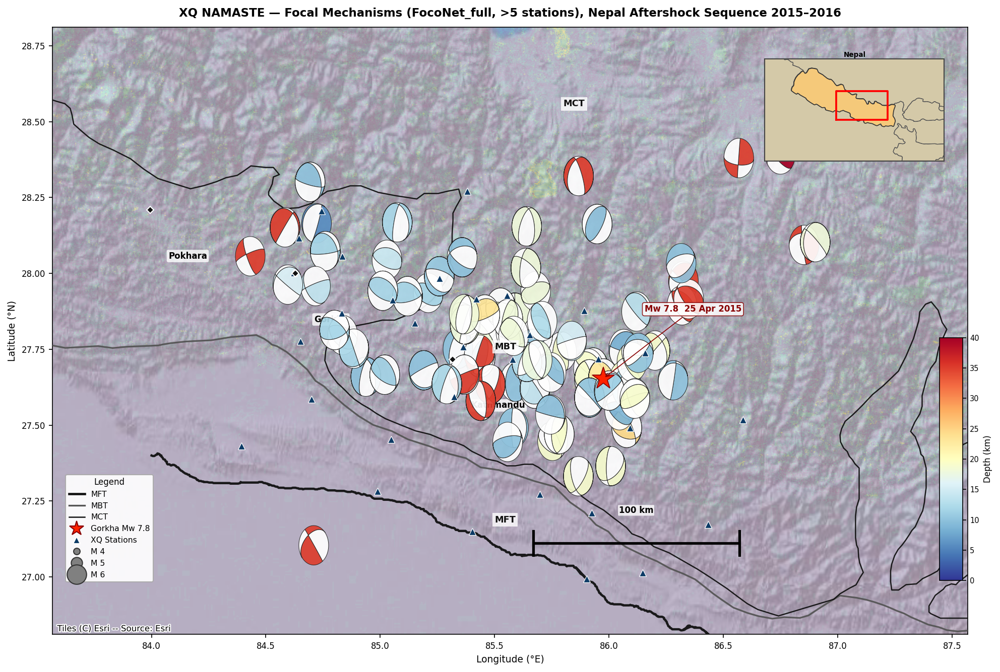

Saved → XQ_foconet_full_map_95_5S.png  (88 events plotted)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import pandas as pd
import geopandas as gpd
import cartopy.io.shapereader as shpreader
import contextily as ctx
from obspy.imaging.beachball import beach
from PIL import Image

# __Load FocoNet predictions ___________________________________________________
df_foco = pd.read_csv('predictions.csv')

df_foco['time_label'] = df_foco['folder_name'].str.extract(r'^(\d{8}T\d{6})')
df_foco['magnitude']  = df_foco['folder_name'].str.extract(r'_M([\d.]+)').astype(float)

# __Load station counts ________________________________________________________
xq_data = np.load('XQ_dataset.npy', allow_pickle=True).item()
station_counts = {key: val['stationxyz'].shape[0] for key, val in xq_data.items()}
df_foco['n_stations'] = df_foco['folder_name'].map(station_counts)

# __Merge with df_wave _________________________________________________________
df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')
df_foco = df_foco.merge(
    df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
    on='time_label', how='left'
).dropna(subset=['latitude', 'longitude', 'depth_km'])

n_before = len(df_foco)
df_foco = df_foco[df_foco['n_stations'] > 5].reset_index(drop=True)
print(f"FocoNet events with coordinates: {n_before}")
print(f"FocoNet events with >5 stations: {len(df_foco)} (dropped {n_before - len(df_foco)})")

# __Map extent _________________________________________________________________
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2, lon_c + 2
lat_min, lat_max = lat_c - 1, lat_c + 1

fig, ax = plt.subplots(figsize=(13, 9), dpi=150)

# __Basemap ____________________________________________________________________
bg_arr = np.load('nepal_bg.npy')
ax.imshow(bg_arr,
          extent=[lon_min, lon_max, lat_min, lat_max],
          origin='upper', aspect='auto',
          zorder=0, alpha=0.75,
          interpolation='bilinear')
ax.set_facecolor('#c8d8e8')

for source in [ctx.providers.Esri.WorldShadedRelief,
               ctx.providers.Esri.WorldTopoMap,
               ctx.providers.OpenTopoMap]:
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=source,
                        zoom=8, alpha=0.65, zorder=0)
        print(f"Basemap: {source['name']}")
        break
    except Exception as e:
        print(f"Skipped: {e}")

# __Fault traces from digitized data ___________________________________________
def load_fault(path):
    lons, lats = [], []
    with open(path) as f:
        for line in f:
            parts = line.strip().replace(',', ' ').split()
            if len(parts) >= 2:
                try:
                    lons.append(float(parts[0]))
                    lats.append(float(parts[1]))
                except:
                    pass
    return np.array(lons), np.array(lats)

mft_lon, mft_lat = load_fault('fault/mft.dat')
mbt_lon, mbt_lat = load_fault('fault/MBT-new.txt')
mct_lon, mct_lat = load_fault('fault/MCT-new.txt')

ax.plot(mft_lon, mft_lat, color='#111111', linewidth=2.2, zorder=5, alpha=0.95)
ax.plot(mbt_lon, mbt_lat, color='#555555', linewidth=1.6, zorder=5, alpha=0.95)
ax.plot(mct_lon, mct_lat, color='#111111', linewidth=1.2, zorder=5, alpha=0.95)

# __Fault labels _______________________________________________________________
label_kw = dict(fontsize=8.5, fontweight='bold', color='#111111', zorder=11,
                bbox=dict(facecolor='white', alpha=0.80, edgecolor='none', pad=2))
ax.text(85.8, 28.55, 'MCT', **label_kw)
ax.text(85.5, 27.18, 'MFT', **label_kw)
ax.text(85.5, 27.75, 'MBT', **label_kw)

# __Beach balls coloured by depth ______________________________________________
cmap_bb = cm.RdYlBu_r
norm_bb = Normalize(vmin=0, vmax=40)

for _, row in df_foco.iterrows():
    width = max(0.13, min(0.50, 0.028 * (3 ** (row['magnitude'] - 3.5))))
    color = cmap_bb(norm_bb(row['depth_km']))
    try:
        b = beach(
            [row['strike'], row['dip'], row['rake']],
            xy=(row['longitude'], row['latitude']),
            width=width,
            linewidth=0.5,
            facecolor=color,
            bgcolor='white',
            edgecolor='#222222',
            alpha=0.92,
            zorder=7
        )
        ax.add_collection(b)
    except Exception:
        pass

# __Mainshock star _____________________________________________________________
ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'],
        marker='*', color='#FF2200', markersize=22,
        markeredgecolor='#880000', markeredgewidth=0.8,
        linestyle='None', zorder=10)
ax.annotate("Mw 7.8  25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.18, ms['latitude'] + 0.22),
            fontsize=8, fontweight='bold', color='#880000', zorder=11,
            arrowprops=dict(arrowstyle='->', color='#880000', lw=0.8),
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                      alpha=0.85, edgecolor='#880000', linewidth=0.8))

# __Stations ___________________________________________________________________
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', markeredgewidth=0.6,
        linestyle='None', zorder=8)

# __Cities _____________________________________________________________________
for name, (lo, la) in {'Kathmandu': (85.316, 27.717),
                        'Pokhara':   (83.994, 28.209),
                        'Gorkha':    (84.630, 28.000)}.items():
    ax.plot(lo, la, marker='D', color='#111111', markersize=5,
            markeredgecolor='white', linestyle='None', zorder=9)
    ax.annotate(name, xy=(lo, la), xytext=(lo + 0.08, la - 0.16),
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          alpha=0.80, edgecolor='none'))

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# __Depth colorbar _____________________________________________________________
cax = inset_axes(ax, width="2.5%", height="40%", loc='lower right',
                 bbox_to_anchor=(0.0, 0.08, 1, 1), bbox_transform=ax.transAxes)
cb  = ColorbarBase(cax, cmap=cmap_bb, norm=norm_bb, orientation='vertical')
cb.set_label('Depth (km)', fontsize=8)
cb.ax.tick_params(labelsize=7)

# __Legend _____________________________________________________________________
mag_legend = [
    mlines.Line2D([], [], linestyle='None', marker='o', color='gray',
                  markeredgecolor='#333333',
                  markersize=max(4, min(20, np.sqrt(0.028 * (3**(m-3.5))) * 28)),
                  label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0]
]
base_handles = [
    mlines.Line2D([], [], color='#111111', linewidth=2.2, label='MFT'),
    mlines.Line2D([], [], color='#555555', linewidth=1.6, label='MBT'),
    mlines.Line2D([], [], color='#111111', linewidth=1.2, label='MCT'),
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=14, markeredgecolor='#880000', label='Gorkha Mw 7.8'),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
]
ax.legend(handles=base_handles + mag_legend,
          loc='lower left', fontsize=7.5, framealpha=0.92,
          edgecolor='#AAAAAA', title='Legend', title_fontsize=8,
          bbox_to_anchor=(0.01, 0.08))

# __Inset map __________________________________________________________________
ax_in = inset_axes(ax, width="20%", height="22%", loc='upper right',
                   bbox_to_anchor=(0, 0, 0.98, 0.98),
                   bbox_transform=ax.transAxes)
ax_in.set_xlim(78, 92); ax_in.set_ylim(24, 31)
ax_in.set_facecolor('#a8c8e8')

land_path = shpreader.natural_earth(resolution='50m', category='physical', name='land')
land_gdf  = gpd.read_file(land_path).clip([78, 24, 92, 31])
land_gdf.plot(ax=ax_in, facecolor='#d4c9a8', edgecolor='#888888', linewidth=0.4, zorder=1)

borders_path = shpreader.natural_earth(resolution='50m', category='cultural',
                                       name='admin_0_countries')
borders_gdf  = gpd.read_file(borders_path).clip([78, 24, 92, 31])
borders_gdf.plot(ax=ax_in, facecolor='none', edgecolor='#555555', linewidth=0.6, zorder=2)
borders_gdf[borders_gdf['NAME'] == 'Nepal'].plot(
    ax=ax_in, facecolor='#f5c97a', edgecolor='#333333', linewidth=0.8, zorder=3)

rect_x = [lon_min, lon_max, lon_max, lon_min, lon_min]
rect_y = [lat_min, lat_min, lat_max, lat_max, lat_min]
ax_in.plot(rect_x, rect_y, 'r-', linewidth=1.8, zorder=5)
ax_in.set_xticks([]); ax_in.set_yticks([])
ax_in.set_title('Nepal', fontsize=6.5, pad=2, fontweight='bold')
for spine in ax_in.spines.values():
    spine.set_edgecolor('#444444'); spine.set_linewidth(1.0)

# __Scale bar __________________________________________________________________
scale_deg = 100 / 111.0
x0, y0 = lon_max - 1.9, lat_min + 0.3
ax.plot([x0, x0+scale_deg], [y0, y0], color='black', linewidth=2.5,
        zorder=10, solid_capstyle='butt')
ax.plot([x0, x0],         [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.plot([x0+scale_deg]*2, [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.text(x0+scale_deg/2, y0+0.10, '100 km', ha='center', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_title('XQ NAMASTE — Focal Mechanisms (FocoNet_full, >5 stations), Nepal Aftershock Sequence 2015–2016',
             fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Longitude (°E)', fontsize=9)
ax.set_ylabel('Latitude (°N)', fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig('XQ_foconet_full_map_95_5S.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved → XQ_foconet_full_map_95_5S.png  ({len(df_foco)} events plotted)")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import make_interp_spline
import numpy as np
import pandas as pd
import geopandas as gpd
import cartopy.io.shapereader as shpreader
import contextily as ctx
from obspy.imaging.beachball import beach
from obspy.geodetics import gps2dist_azimuth
from PIL import Image

# __Load FocoNet_SP predictions _________________________________________________
df_foco = pd.read_csv('predictions.csv')

# foconet_sp_xq.csv uses 'event' (not 'folder_name') and gives BOTH nodal planes
# (strike1/dip1/rake1, strike2/dip2/rake2) instead of a single strike/dip/rake.
# We use plane 1 for the beachball — the conjugate plane (plane 2) represents
# the same focal mechanism, so either is geometrically valid to plot.
df_foco['time_label'] = df_foco['folder_name'].str.extract(r'^(\d{8}T\d{6})') # Changed from 'event' to 'folder_name'
df_foco['magnitude']  = df_foco['folder_name'].str.extract(r'_M([\d.]+)').astype(float) # Changed from 'event' to 'folder_name'
df_foco = df_foco.rename(columns={
    'strike1': 'strike', 'dip1': 'dip', 'rake1': 'rake'
})

# __Load station counts per event from the .npy dataset ________________________
xq_data = np.load('XQ_dataset.npy', allow_pickle=True).item()
station_counts = {key: val['stationxyz'].shape[0] for key, val in xq_data.items()}
df_foco['n_stations'] = df_foco['folder_name'].map(station_counts) # Changed from 'event' to 'folder_name'

# Merge with df_wave to get lat/lon/depth using time label
df_wave['time_label'] = pd.to_datetime(df_wave['time']).dt.strftime('%Y%m%dT%H%M%S')
df_foco = df_foco.merge(
    df_wave[['time_label', 'latitude', 'longitude', 'depth_km']],
    on='time_label', how='left'
).dropna(subset=['latitude', 'longitude', 'depth_km'])

# __Azimuthal gap / network-coverage quality ____________________________________
# Uses the full XQ station inventory (XQ_inventory.xml, already read into `inv`)
# to compute the worst azimuthal gap as seen from each event location, then
# classifies network coverage the same way as the main df_wave quality flag.
def compute_azimuthal_gap(ev_lat, ev_lon, inv):
    azimuths = []
    for net in inv:
        for sta in net:
            _, az, _ = gps2dist_azimuth(ev_lat, ev_lon, sta.latitude, sta.longitude)
            azimuths.append(az % 360)
    if len(azimuths) < 2:
        return 360.0
    azimuths = sorted(azimuths)
    gaps = [azimuths[i+1] - azimuths[i] for i in range(len(azimuths)-1)]
    gaps.append(360 - azimuths[-1] + azimuths[0])
    return max(gaps)

def quality(az_gap, n_sta):
    if az_gap < 90 and n_sta >= 10:  return 'Excellent'
    elif az_gap < 180 and n_sta >= 6: return 'Good'
    elif az_gap < 270:                return 'Poor'
    else:                             return 'Unusable'

print('Computing azimuthal gaps for FocoNet_SP events ...')
df_foco['az_gap'] = df_foco.apply(
    lambda row: compute_azimuthal_gap(row['latitude'], row['longitude'], inv), axis=1
)
df_foco['quality'] = df_foco.apply(
    lambda row: quality(row['az_gap'], row['n_stations']), axis=1
)

# __Filter: keep only events with >5 stations AND good network coverage ________
n_before = len(df_foco)
df_foco = df_foco[
    (df_foco['n_stations'] > 5) &
    (df_foco['quality'].isin(['Excellent', 'Good']))
].reset_index(drop=True)

print(f"FocoNet_SP events with coordinates: {n_before}")
print(f"FocoNet_SP events kept (>5 stations & Excellent/Good network coverage): {len(df_foco)} "
      f"(dropped {n_before - len(df_foco)})")
print(df_foco['quality'].value_counts())

# __Map extent _________________________________________________________________
lon_c = df_wave['longitude'].mean()
lat_c = df_wave['latitude'].mean()
lon_min, lon_max = lon_c - 2, lon_c + 2
lat_min, lat_max = lat_c - 1, lat_c + 1

fig, ax = plt.subplots(figsize=(13, 9), dpi=150)

# __Basemap ____________________________________________________________________
bg_arr = np.load('nepal_bg.npy')
ax.imshow(bg_arr,
          extent=[lon_min, lon_max, lat_min, lat_max],
          origin='upper', aspect='auto',
          zorder=0, alpha=0.75,
          interpolation='bilinear')
ax.set_facecolor('#c8d8e8')

for source in [ctx.providers.Esri.WorldShadedRelief,
               ctx.providers.Esri.WorldTopoMap,
               ctx.providers.OpenTopoMap]:
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=source,
                        zoom=8, alpha=0.65, zorder=0)
        print(f"Basemap: {source['name']}")
        break
    except Exception as e:
        print(f"Skipped: {e}")

# __GEM reverse faults _________________________________________________________
reverse_faults = faults_nepal[faults_nepal['slip_type'] == 'Reverse']
reverse_faults.plot(ax=ax, color='#111111', linewidth=2.2, zorder=5, alpha=0.95)

# __MCT trace (smoothed + clipped to map extent) _______________________________
mct_lon_raw = np.array([
    80.0, 80.2, 80.4, 80.6, 80.8, 81.0, 81.2, 81.4, 81.6, 81.8,
    82.0, 82.2, 82.4, 82.6, 82.8, 83.0, 83.2, 83.4, 83.6, 83.8,
    84.0, 84.1, 84.2, 84.3, 84.4, 84.5, 84.6, 84.7, 84.8, 84.9,
    85.0, 85.1, 85.2, 85.3, 85.4, 85.5, 85.6, 85.7, 85.8, 85.9,
    86.0, 86.1, 86.2, 86.3, 86.4, 86.5, 86.6, 86.7, 86.8, 86.9,
    87.0, 87.1, 87.2, 87.3, 87.4, 87.5, 87.6, 87.7, 87.8, 87.9,
    88.0, 88.1, 88.2, 88.3, 88.4
])
mct_lat_raw = np.array([
    30.35, 30.28, 30.20, 30.12, 30.02, 29.92, 29.80, 29.68, 29.55, 29.42,
    29.28, 29.18, 29.10, 29.02, 28.94, 28.86, 28.78, 28.72, 28.66, 28.60,
    28.55, 28.52, 28.50, 28.47, 28.45, 28.42, 28.40, 28.38, 28.36, 28.34,
    28.32, 28.30, 28.28, 28.26, 28.25, 28.23, 28.21, 28.19, 28.17, 28.15,
    28.13, 28.11, 28.09, 28.07, 28.05, 28.03, 28.01, 27.99, 27.97, 27.95,
    27.93, 27.91, 27.89, 27.87, 27.85, 27.83, 27.81, 27.79, 27.77, 27.75,
    27.72, 27.69, 27.66, 27.62, 27.58
])

margin = 0.5
mask = (mct_lon_raw >= lon_min - margin) & (mct_lon_raw <= lon_max + margin)
mct_lon_clip = mct_lon_raw[mask]
mct_lat_clip = mct_lat_raw[mask]

if len(mct_lon_clip) >= 4:
    t = np.linspace(0, 1, len(mct_lon_clip))
    t_smooth = np.linspace(0, 1, 300)
    spl_lon = make_interp_spline(t, mct_lon_clip, k=3)
    spl_lat = make_interp_spline(t, mct_lat_clip, k=3)
    mct_lon_plot, mct_lat_plot = spl_lon(t_smooth), spl_lat(t_smooth)
else:
    mct_lon_plot, mct_lat_plot = mct_lon_clip, mct_lat_clip

ax.plot(mct_lon_plot, mct_lat_plot, color='#111111', linewidth=1.6,
        linestyle='--', zorder=5, solid_capstyle='round')

# Fault labels
label_kw = dict(fontsize=8.5, fontweight='bold', color='#111111', zorder=11,
                bbox=dict(facecolor='white', alpha=0.80, edgecolor='none', pad=2))
ax.text(85.8, 28.55, 'MCT', **label_kw)
ax.text(85.5, 27.18, 'MFT', **label_kw)

# __Beach balls coloured by depth _____________________________________________
cmap_bb = cm.RdYlBu_r
norm_bb = Normalize(vmin=0, vmax=40)

for _, row in df_foco.iterrows():
    width = max(0.13, min(0.50, 0.028 * (3 ** (row['magnitude'] - 3.5))))
    color = cmap_bb(norm_bb(row['depth_km']))
    try:
        b = beach(
            [row['strike'], row['dip'], row['rake']],
            xy=(row['longitude'], row['latitude']),
            width=width,
            linewidth=0.5,
            facecolor=color,
            bgcolor='white',
            edgecolor='#222222',
            alpha=0.92,
            zorder=7
        )
        ax.add_collection(b)
    except Exception:
        pass

# __Mainshock star _____________________________________________________________
ms = df_wave.loc[df_wave['magnitude'].idxmax()]
ax.plot(ms['longitude'], ms['latitude'],
        marker='*', color='#FF2200', markersize=22,
        markeredgecolor='#880000', markeredgewidth=0.8,
        linestyle='None', zorder=10)
ax.annotate("Mw 25 Apr 2015",
            xy=(ms['longitude'], ms['latitude']),
            xytext=(ms['longitude'] + 0.18, ms['latitude'] + 0.22),
            fontsize=8, fontweight='bold', color='#880000', zorder=11,
            arrowprops=dict(arrowstyle='->', color='#880000', lw=0.8),
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                      alpha=0.85, edgecolor='#880000', linewidth=0.8))

# __Stations ___________________________________________________________________
ax.plot(df_sta['longitude'], df_sta['latitude'],
        marker='^', color='#0D3B66', markersize=7,
        markeredgecolor='white', markeredgewidth=0.6,
        linestyle='None', zorder=8)

# __Cities _____________________________________________________________________
for name, (lo, la) in {'Kathmandu': (85.316, 27.717),
                        'Pokhara':   (83.994, 28.209),
                        'Gorkha':    (84.630, 28.000)}.items():
    ax.plot(lo, la, marker='D', color='#111111', markersize=5,
            markeredgecolor='white', linestyle='None', zorder=9)
    ax.annotate(name, xy=(lo, la), xytext=(lo + 0.08, la - 0.16),
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          alpha=0.80, edgecolor='none'))

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# __Depth colorbar _____________________________________________________________
cax = inset_axes(ax, width="2.5%", height="40%", loc='lower right',
                 bbox_to_anchor=(0.0, 0.08, 1, 1), bbox_transform=ax.transAxes)
cb  = ColorbarBase(cax, cmap=cmap_bb, norm=norm_bb, orientation='vertical')
cb.set_label('Depth (km)', fontsize=8)
cb.ax.tick_params(labelsize=7)

# __Legend _____________________________________________________________________
mag_legend = [
    mlines.Line2D([], [], linestyle='None', marker='o', color='gray',
                  markeredgecolor='#333333',
                  markersize=max(4, min(20, np.sqrt(0.028 * (3**(m-3.5))) * 28)),
                  label=f'M {m:.0f}')
    for m in [4.0, 5.0, 6.0]
]
base_handles = [
    mlines.Line2D([], [], color='#111111', linewidth=2.2, label='MFT (GEM)'),
    mlines.Line2D([], [], color='#111111', linewidth=1.6, linestyle='--', label='MCT'),
    mlines.Line2D([], [], linestyle='None', marker='*', color='#FF2200',
                  markersize=14, markeredgecolor='#880000', label='Gorkha Mw 7.8'),
    mlines.Line2D([], [], linestyle='None', marker='^', color='#0D3B66',
                  markersize=7, markeredgecolor='white', label='XQ Stations'),
]
ax.legend(handles=base_handles + mag_legend,
          loc='lower left', fontsize=7.5, framealpha=0.92,
          edgecolor='#AAAAAA', title='Legend', title_fontsize=8,
          bbox_to_anchor=(0.01, 0.08))

# __Inset map __________________________________________________________________
ax_in = inset_axes(ax, width="20%", height="22%", loc='upper right',
                   bbox_to_anchor=(0, 0, 0.98, 0.98),
                   bbox_transform=ax.transAxes)
ax_in.set_xlim(78, 92); ax_in.set_ylim(24, 31)
ax_in.set_facecolor('#a8c8e8')

land_path = shpreader.natural_earth(resolution='50m', category='physical', name='land')
land_gdf  = gpd.read_file(land_path).clip([78, 24, 92, 31])
land_gdf.plot(ax=ax_in, facecolor='#d4c9a8', edgecolor='#888888', linewidth=0.4, zorder=1)

borders_path = shpreader.natural_earth(resolution='50m', category='cultural',
                                       name='admin_0_countries')
borders_gdf  = gpd.read_file(borders_path).clip([78, 24, 92, 31])
borders_gdf.plot(ax=ax_in, facecolor='none', edgecolor='#555555', linewidth=0.6, zorder=2)
borders_gdf[borders_gdf['NAME'] == 'Nepal'].plot(
    ax=ax_in, facecolor='#f5c97a', edgecolor='#333333', linewidth=0.8, zorder=3)

rect_x = [lon_min, lon_max, lon_max, lon_min, lon_min]
rect_y = [lat_min, lat_min, lat_max, lat_max, lat_min]
ax_in.plot(rect_x, rect_y, 'r-', linewidth=1.8, zorder=5)
ax_in.set_xticks([]); ax_in.set_yticks([])
ax_in.set_title('Nepal', fontsize=6.5, pad=2, fontweight='bold')
for spine in ax_in.spines.values():
    spine.set_edgecolor('#444444'); spine.set_linewidth(1.0)

# __Scale bar __________________________________________________________________
scale_deg = 100 / 111.0
x0, y0 = lon_max - 1.9, lat_min + 0.3
ax.plot([x0, x0+scale_deg], [y0, y0], color='black', linewidth=2.5,
        zorder=10, solid_capstyle='butt')
ax.plot([x0, x0],         [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.plot([x0+scale_deg]*2, [y0-0.04, y0+0.04], color='black', linewidth=2.5, zorder=10)
ax.text(x0+scale_deg/2, y0+0.10, '100 km', ha='center', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_title('XQ NAMASTE — Focal Mechanisms (FocoNet_SP, >5 stations, good network coverage),\nNepal Aftershock Sequence 2015–2016',
             fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Longitude (°E)', fontsize=9)
ax.set_ylabel('Latitude (°N)', fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig('XQ_foconet_sp_map_filtered.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved → XQ_foconet_sp_map_filtered.png  ({len(df_foco)} events plotted)")

FileNotFoundError: [Errno 2] No such file or directory: 'XQ_dataset.npy'